In [307]:
import pandas as pd
import numpy as np

spy_data = pd.read_csv('../data/raw/markets/SPY.csv')
df_spy = pd.DataFrame(spy_data)
print(df_spy.head())
print(df_spy.tail())
print(df_spy.info())
print(df_spy.describe())
print(df_spy.columns)
info_df = pd.DataFrame({
    'Dtype': df_spy.dtypes,
    'Non-Null Count': df_spy.notnull().sum(),
    'Null Count': df_spy.isnull().sum()
})
print(info_df)

vix_data = pd.read_csv('../data/raw/vix/VIX_History.csv')
df_vix = pd.DataFrame(vix_data)
print('\nVIX DATA:')
print(df_vix.head())
print(df_vix.tail())

         date     open     high      low    close   volume  adjusted_close  \
0  1993-01-29  43.8595  43.9688  43.7500  43.9375  1003200         24.7677   
1  1993-02-01  43.9688  44.2500  43.9688  44.2500   480500         24.9438   
2  1993-02-02  44.2188  44.3750  44.1250  44.3438   201300         24.9967   
3  1993-02-03  44.4063  44.8438  44.3750  44.8125   529400         25.2609   
4  1993-02-04  44.9688  45.0938  44.8750  45.0000   531500         25.3666   

   change_percent  avg_vol_20d  
0             NaN          NaN  
1            0.71          NaN  
2            0.21          NaN  
3            1.06          NaN  
4            0.42          NaN  
            date    open    high     low   close    volume  adjusted_close  \
7853  2024-04-09  520.50  520.75  514.35  519.32  68124400          519.32   
7854  2024-04-10  513.48  516.16  512.09  514.12  82652800          514.12   
7855  2024-04-11  515.68  519.48  512.08  518.00  70099000          518.00   
7856  2024-04-12  514

In [308]:
df_spy['date'] = pd.to_datetime(df_spy['date'], format='%Y-%m-%d')
df_vix['DATE'] = pd.to_datetime(df_vix['DATE'], format='%m/%d/%Y')

df_market = pd.merge(df_spy, df_vix, how='inner', left_on='date', right_on='DATE')
df_market.drop(columns=['DATE'])
df_market = df_market.rename({'open': 'spy_open', 'high': 'spy_high', 'low': 'spy_low', 'close': 'spy_close', 'volume': 'spy_volume', 
                  'adjusted_close': 'spy_adj_close', 'change_percent': 'spy_change_percent', 'avg_vol_20d': 'spy_avg_vol_20d',
                  'OPEN': 'vix_open', 'HIGH': 'vix_high', 'LOW': 'vix_low', 'CLOSE': 'vix_close'}, axis=1)
print('\nMERGED DATA:')
print(df_market.head())
print(df_market.tail())
info_df = pd.DataFrame({
    'Dtype': df_market.dtypes,
    'Non-Null Count': df_market.notnull().sum(),
    'Null Count': df_market.isnull().sum()
})
print(info_df)


MERGED DATA:
        date  spy_open  spy_high  spy_low  spy_close  spy_volume  \
0 1993-01-29   43.8595   43.9688  43.7500    43.9375     1003200   
1 1993-02-01   43.9688   44.2500  43.9688    44.2500      480500   
2 1993-02-02   44.2188   44.3750  44.1250    44.3438      201300   
3 1993-02-03   44.4063   44.8438  44.3750    44.8125      529400   
4 1993-02-04   44.9688   45.0938  44.8750    45.0000      531500   

   spy_adj_close  spy_change_percent  spy_avg_vol_20d       DATE  vix_open  \
0        24.7677                 NaN              NaN 1993-01-29     12.49   
1        24.9438                0.71              NaN 1993-02-01     12.51   
2        24.9967                0.21              NaN 1993-02-02     12.47   
3        25.2609                1.06              NaN 1993-02-03     11.98   
4        25.3666                0.42              NaN 1993-02-04     11.86   

   vix_high  vix_low  vix_close  
0     13.16    12.42      12.42  
1     12.92    12.18      12.33  
2     

In [309]:
print('Duplicate dates: ', df_market['date'].duplicated().sum())

price_cols = ['spy_open', 'spy_high', 'spy_low', 'spy_close', 'spy_adj_close', 'vix_open', 'vix_high', 'vix_low', 'vix_close']
print((df_market[price_cols] < 0).sum())

print('SPY:')
print((df_market['spy_high'] < df_market['spy_low']).sum())
print((df_market['spy_open'] < df_market['spy_low']).sum())
print((df_market['spy_close'] < df_market['spy_low']).sum())
print((df_market['spy_high'] < df_market['spy_open']).sum())
print((df_market['spy_high'] < df_market['spy_close']).sum())

print('VIX:')
print((df_market['vix_high'] < df_market['vix_low']).sum())
print((df_market['vix_open'] < df_market['vix_low']).sum())
print((df_market['vix_close'] < df_market['vix_low']).sum())
print((df_market['vix_high'] < df_market['vix_open']).sum())
print((df_market['vix_high'] < df_market['vix_close']).sum())
print()
print(df_market[df_market['vix_close'] < df_market['vix_low']])

df_market = df_market.drop(df_market[df_market['vix_close'] < df_market['vix_low']].index)
df_market = df_market.drop(df_market[df_market['vix_open'] < df_market['vix_low']].index)
df_market = df_market.drop(df_market[df_market['vix_high'] < df_market['vix_open']].index)

Duplicate dates:  0
spy_open         0
spy_high         0
spy_low          0
spy_close        0
spy_adj_close    0
vix_open         0
vix_high         0
vix_low          0
vix_close        0
dtype: int64
SPY:
0
0
0
0
0
VIX:
0
21
1
12
0

           date  spy_open  spy_high  spy_low  spy_close  spy_volume  \
3306 2006-03-20    130.64     130.9   130.21     130.41    45538500   

      spy_adj_close  spy_change_percent  spy_avg_vol_20d       DATE  vix_open  \
3306        92.3269               -0.16       54598049.9 2006-03-20     12.11   

      vix_high  vix_low  vix_close  
3306     12.21    11.82      11.79  


In [310]:
if 'DATE' in df_market.columns:
    df_market = df_market.drop(columns='DATE')

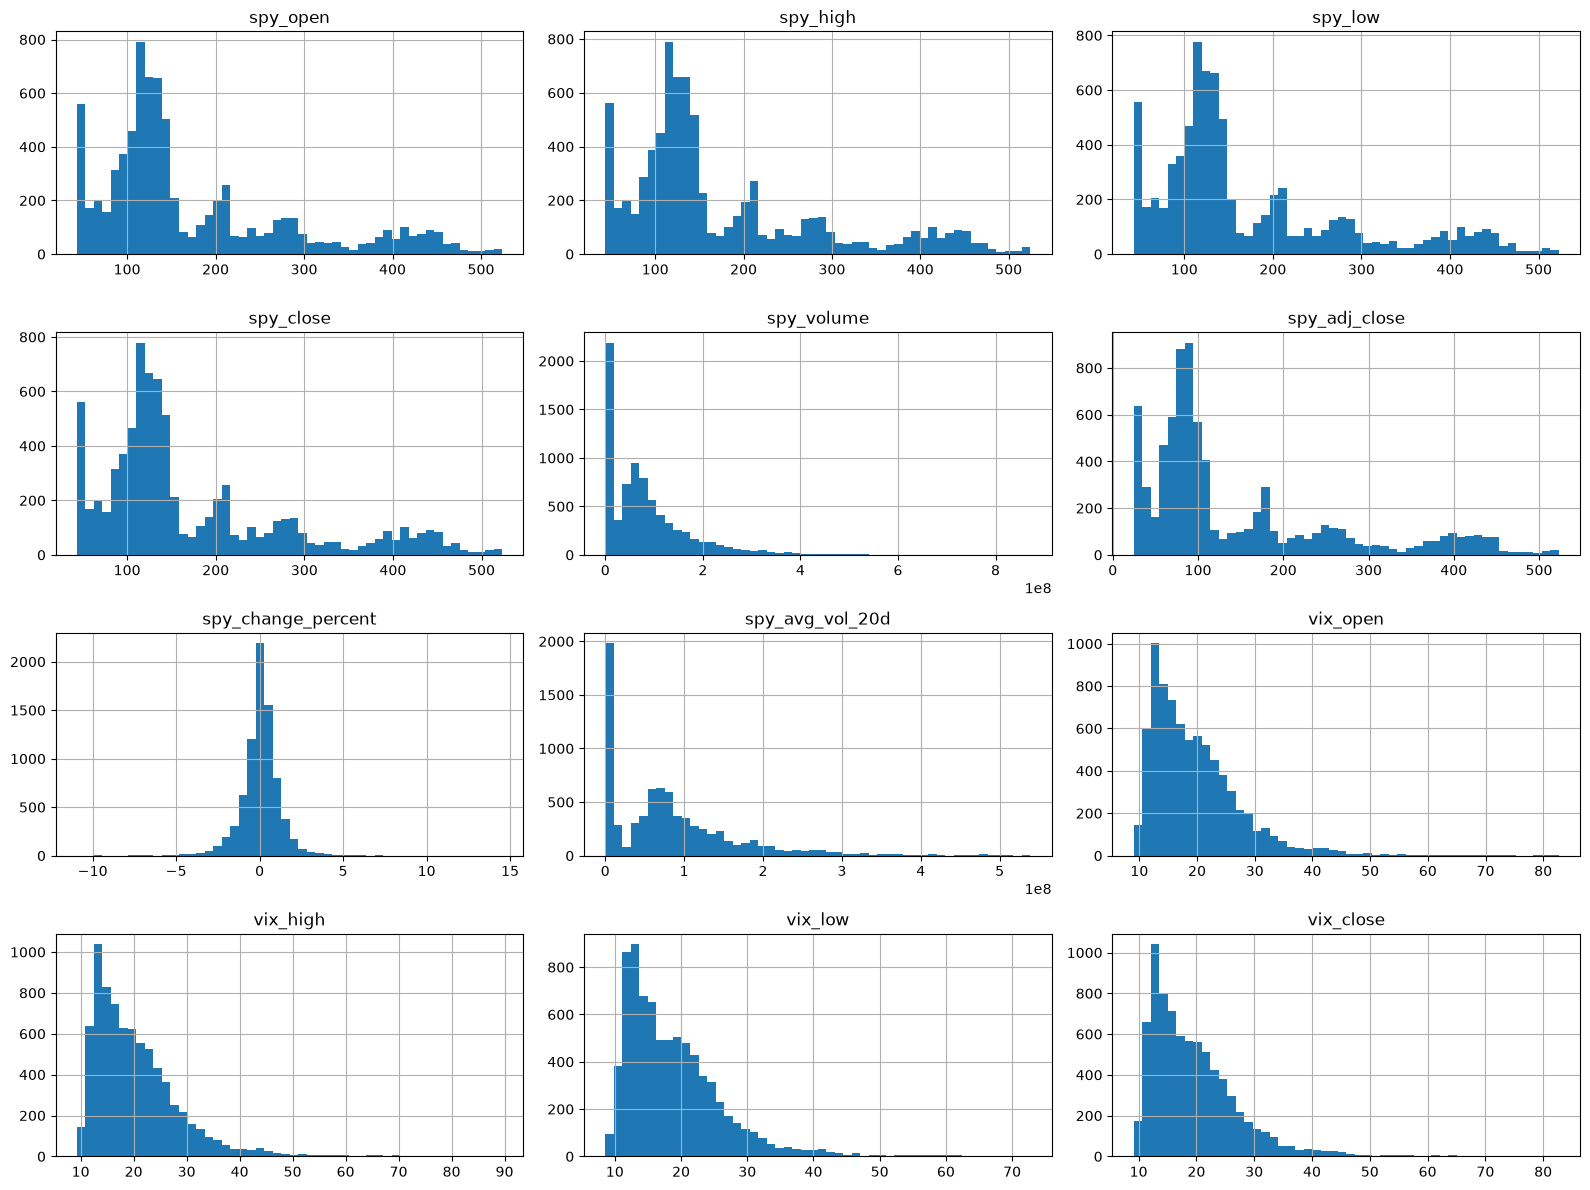

In [311]:
import matplotlib.pyplot as plt
df_market_stats = df_market[['spy_open', 'spy_high', 'spy_low', 'spy_close','spy_volume', 
                             'spy_adj_close', 'spy_change_percent', 'spy_avg_vol_20d', 
                             'vix_open', 'vix_high', 'vix_low', 'vix_close']]
df_market_stats.hist(figsize=(16, 12), bins=50)
plt.tight_layout()
plt.show()

In [312]:
df_spy_opt_2010 = pd.read_parquet('../data/raw/options/spy_eod_2010.parquet')
print('\nSPY OPTIONS 2010 DATA:')
print(df_spy_opt_2010.head())
print(df_spy_opt_2010.tail())
print(df_spy_opt_2010.info())
info_df = pd.DataFrame({
    'Dtype': df_spy_opt_2010.dtypes,
    'Non-Null Count': df_spy_opt_2010.notnull().sum(),
    'Null Count': df_spy_opt_2010.isnull().sum()
})
print(info_df)


SPY OPTIONS 2010 DATA:
   [QUOTE_UNIXTIME]  [QUOTE_READTIME] [QUOTE_DATE]  [QUOTE_TIME_HOURS]  \
0        1262638800  2010-01-04 16:00   2010-01-04                16.0   
1        1262638800  2010-01-04 16:00   2010-01-04                16.0   
2        1262638800  2010-01-04 16:00   2010-01-04                16.0   
3        1262638800  2010-01-04 16:00   2010-01-04                16.0   
4        1262638800  2010-01-04 16:00   2010-01-04                16.0   

   [UNDERLYING_LAST] [EXPIRE_DATE]  [EXPIRE_UNIX]  [DTE]  [C_DELTA]  \
0             113.29    2010-01-15     1263589200   11.0    0.88304   
1             113.29    2010-01-15     1263589200   11.0    0.88398   
2             113.29    2010-01-15     1263589200   11.0    0.88657   
3             113.29    2010-01-15     1263589200   11.0    0.88750   
4             113.29    2010-01-15     1263589200   11.0    0.88970   

   [C_GAMMA]  ...  [P_LAST]  [P_DELTA]  [P_GAMMA]  [P_VEGA]  [P_THETA]  \
0    0.00005  ...      0.02   

In [313]:
df_spy_opt = df_spy_opt_2010
for i in range(2011, 2023):
    df_spy_opt_temp = pd.read_parquet(f'../data/raw/options/spy_eod_{i}.parquet')
    df_spy_opt = pd.merge(df_spy_opt, df_spy_opt_temp, how='outer')


In [314]:

df_spy_opt['[QUOTE_DATE]'] = pd.to_datetime(df_spy_opt['[QUOTE_DATE]'], format='%Y-%m-%d')
print(df_spy_opt.head())
print(df_spy_opt.tail())
info_df = pd.DataFrame({
    'Dtype': df_spy_opt.dtypes,
    'Non-Null Count': df_spy_opt.notnull().sum(),
    'Null Count': df_spy_opt.isnull().sum()
})
print(info_df)

   [QUOTE_UNIXTIME]  [QUOTE_READTIME] [QUOTE_DATE]  [QUOTE_TIME_HOURS]  \
0        1262638800  2010-01-04 16:00   2010-01-04                16.0   
1        1262638800  2010-01-04 16:00   2010-01-04                16.0   
2        1262638800  2010-01-04 16:00   2010-01-04                16.0   
3        1262638800  2010-01-04 16:00   2010-01-04                16.0   
4        1262638800  2010-01-04 16:00   2010-01-04                16.0   

   [UNDERLYING_LAST] [EXPIRE_DATE]  [EXPIRE_UNIX]  [DTE]  [C_DELTA]  \
0             113.29    2010-01-15     1263589200   11.0    0.00220   
1             113.29    2010-01-15     1263589200   11.0    0.00232   
2             113.29    2010-01-15     1263589200   11.0    0.00234   
3             113.29    2010-01-15     1263589200   11.0    0.00243   
4             113.29    2010-01-15     1263589200   11.0    0.00248   

   [C_GAMMA]  ...  [P_LAST]  [P_DELTA]  [P_GAMMA]   [P_VEGA]  [P_THETA]  \
0    0.00063  ...     51.45       -1.0        0.0 -45

In [315]:
df_market = df_market.sort_values('date').copy()

df_market['return'] = df_market['spy_adj_close'].pct_change()

df_market['log_return'] = np.log(df_market['spy_adj_close'] / df_market['spy_adj_close'].shift(1))

for window in [5, 20, 60]:
    df_market[f'return_{window}d'] = (
        df_market['spy_adj_close'] / df_market['spy_adj_close'].shift(window) - 1
    )

    df_market[f'rv_{window}d'] = (
        df_market['log_return'].rolling(window=window).std() * np.sqrt(252)
    )

    df_market[f'variance_{window}d'] = (
        df_market['log_return'].rolling(window=window).apply(lambda x: np.sum(x**2), raw=True)
    )

df_market['drawdown'] = df_market['spy_adj_close'].rolling(
    window=252, min_periods=1
    ).apply(
        lambda x: ((x - x.max()) / x.max()).min()
        )

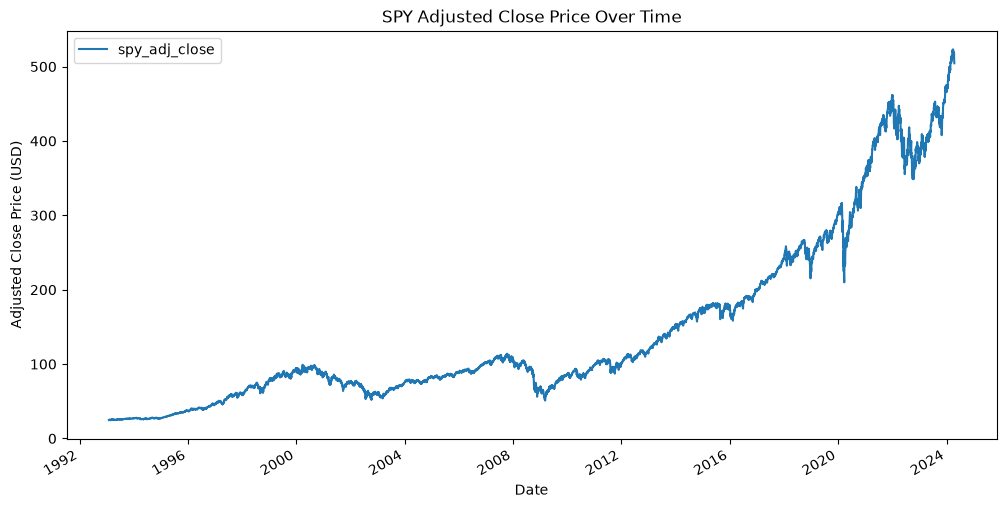

In [316]:
df_market.plot(x='date', y=['spy_adj_close'], figsize=(12, 6))
plt.title('SPY Adjusted Close Price Over Time')
plt.xlabel('Date')
plt.ylabel('Adjusted Close Price (USD)')
plt.show()

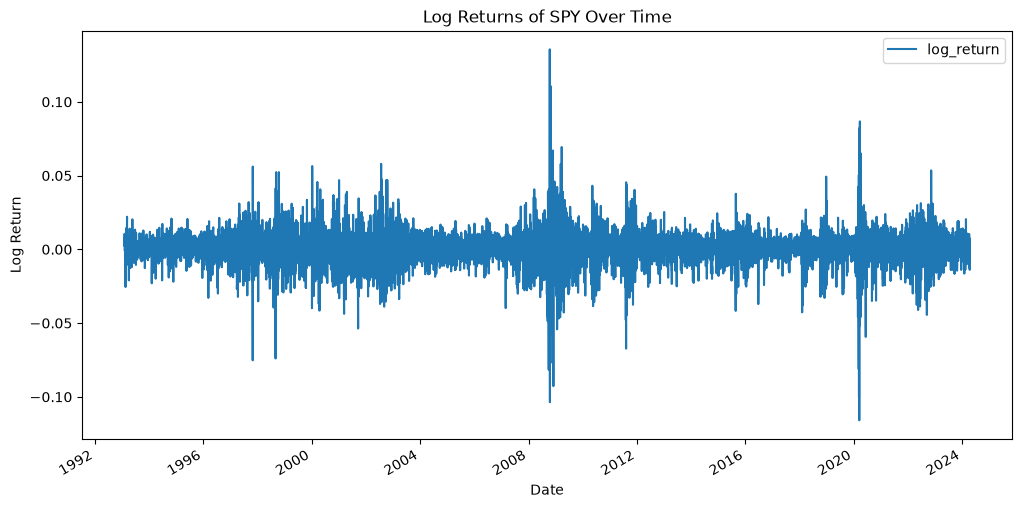

In [317]:
df_market.plot(x='date', y=['log_return'], figsize=(12, 6))
plt.title('Log Returns of SPY Over Time')
plt.xlabel('Date')
plt.ylabel('Log Return')
plt.show()

[]

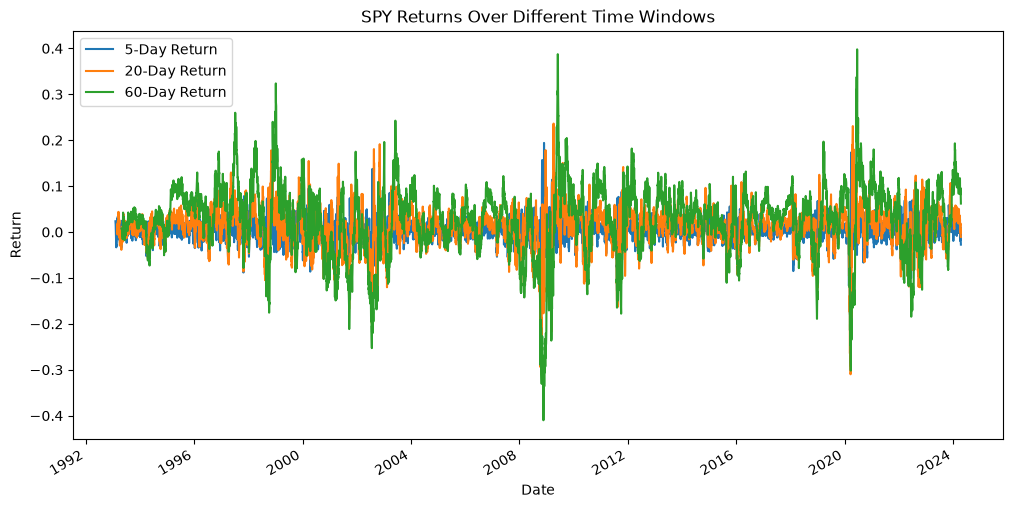

In [318]:
df_market.plot(x='date', y=['return_5d', 'return_20d', 'return_60d'], figsize=(12, 6))
plt.title('SPY Returns Over Different Time Windows')
plt.xlabel('Date')
plt.ylabel('Return')
plt.legend(['5-Day Return', '20-Day Return', '60-Day Return'])

plt.plot()

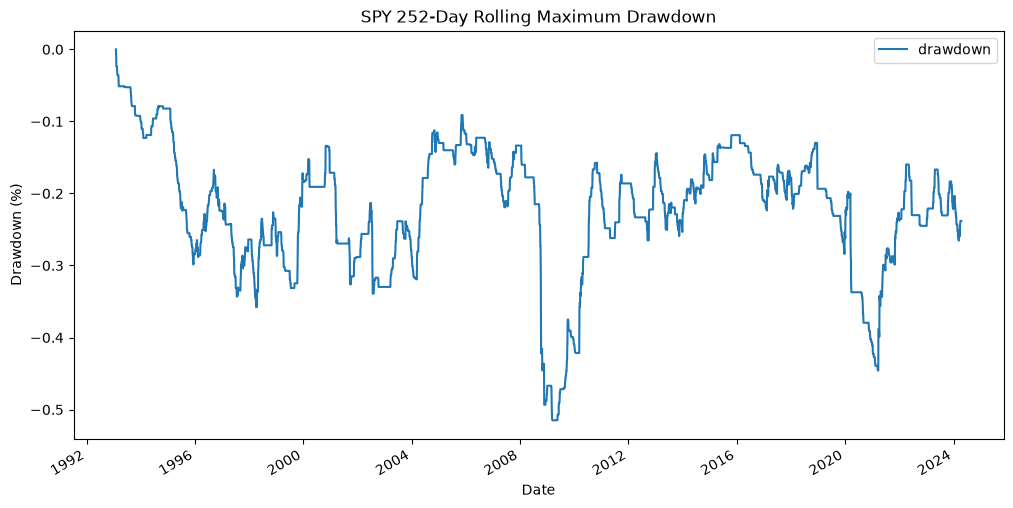

In [319]:
df_market.plot(x='date', y=['drawdown'], figsize=(12, 6))
plt.title('SPY 252-Day Rolling Maximum Drawdown')
plt.xlabel('Date')
plt.ylabel('Drawdown (%)')
plt.show()

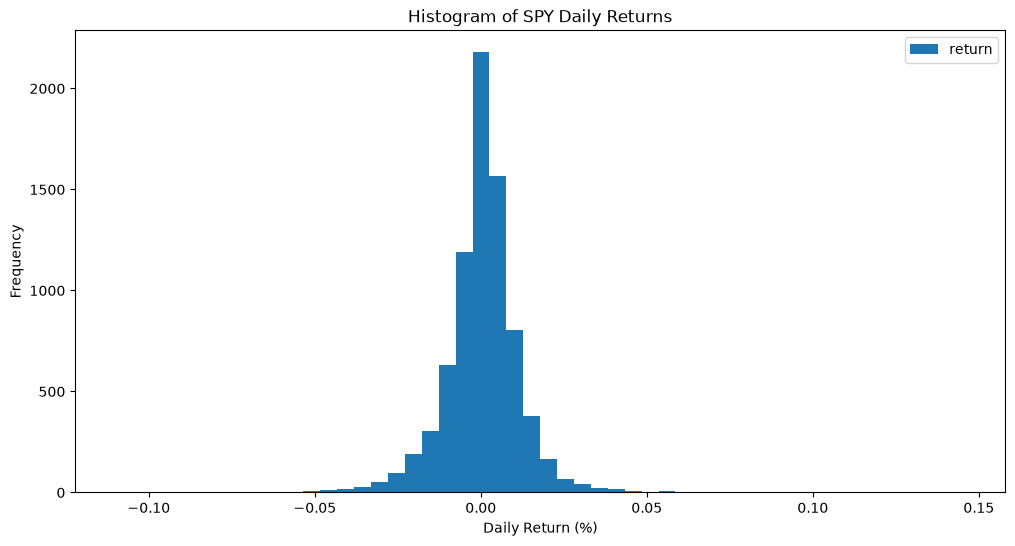

In [320]:
df_market.plot(kind='hist', y='return', bins=50, figsize=(12, 6))
plt.title('Histogram of SPY Daily Returns')
plt.xlabel('Daily Return (%)')
plt.ylabel('Frequency')
plt.show()

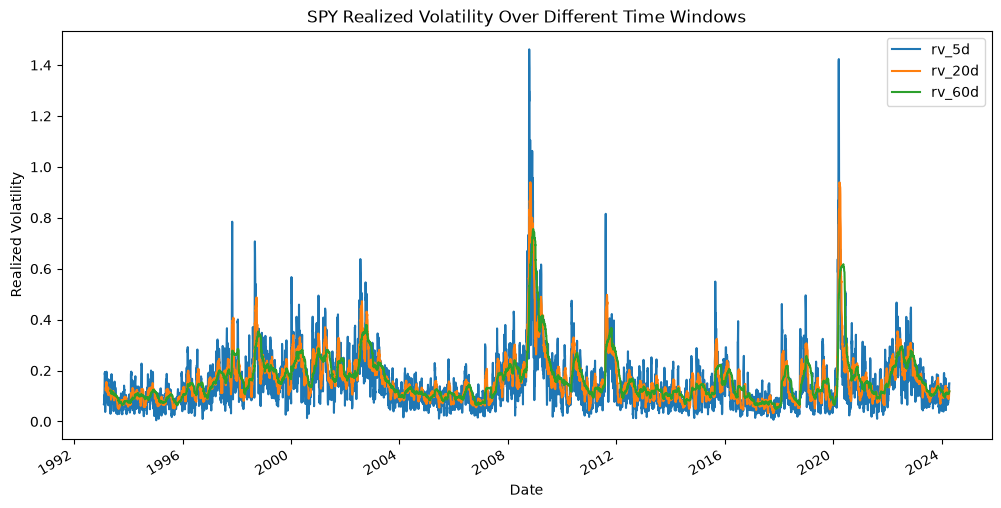

In [321]:
df_market.plot(x='date', y=['rv_5d', 'rv_20d', 'rv_60d'], figsize=(12, 6))
plt.title('SPY Realized Volatility Over Different Time Windows')
plt.xlabel('Date')
plt.ylabel('Realized Volatility')
plt.show()

In [322]:
df_market['vix_pct_change'] = df_market['vix_close'].pct_change()
df_market['vix_log_return'] = np.log(df_market['vix_close'] / df_market['vix_close'].shift(1))
df_market['vix_daily_return'] = df_market['vix_close'].diff()

for window in [5, 20, 60]:
    df_market[f'vix_return_{window}d'] = (
        df_market['vix_close'] / df_market['vix_close'].shift(window) - 1
    )

    df_market[f'vix_rv_{window}d'] = (
        df_market['vix_log_return'].rolling(window=window).std() * np.sqrt(252)
    )

    df_market[f'vix_variance_{window}d'] = (
        df_market['vix_log_return'].rolling(window=window).apply(lambda x: np.sum(x**2), raw=True)
    )

df_market['spread'] = df_market['vix_close'] - df_market['rv_20d']

print('Correlation between SPY return and VIX Daily Change:')
print(df_market['return'].corr(df_market['vix_daily_return']))

Correlation between SPY return and VIX Daily Change:
-0.7917509213772709


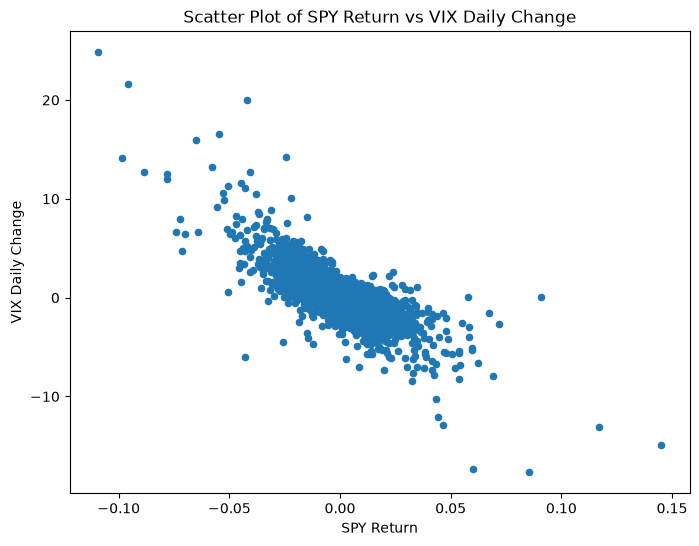

In [323]:
df_market.plot(x='return', y='vix_daily_return', kind='scatter', figsize=(8, 6))
plt.title('Scatter Plot of SPY Return vs VIX Daily Change')
plt.xlabel('SPY Return')
plt.ylabel('VIX Daily Change')
plt.show()

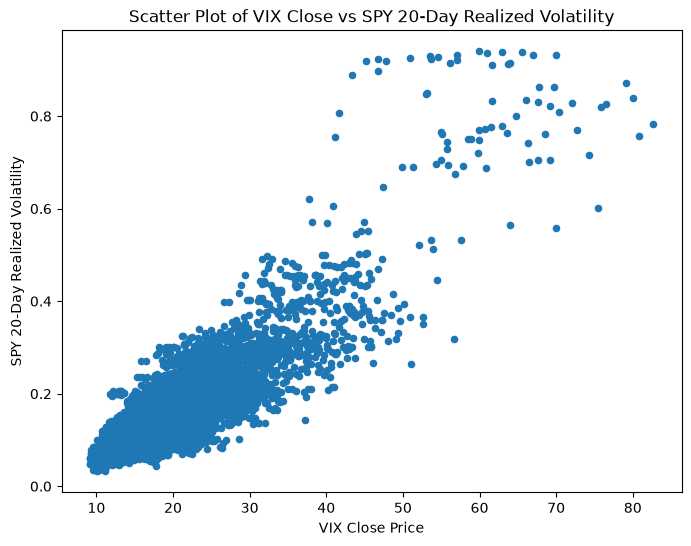

In [324]:
df_market.plot(kind='scatter', x='vix_close', y='rv_20d', figsize=(8, 6))
plt.title('Scatter Plot of VIX Close vs SPY 20-Day Realized Volatility')
plt.xlabel('VIX Close Price')
plt.ylabel('SPY 20-Day Realized Volatility')
plt.show()

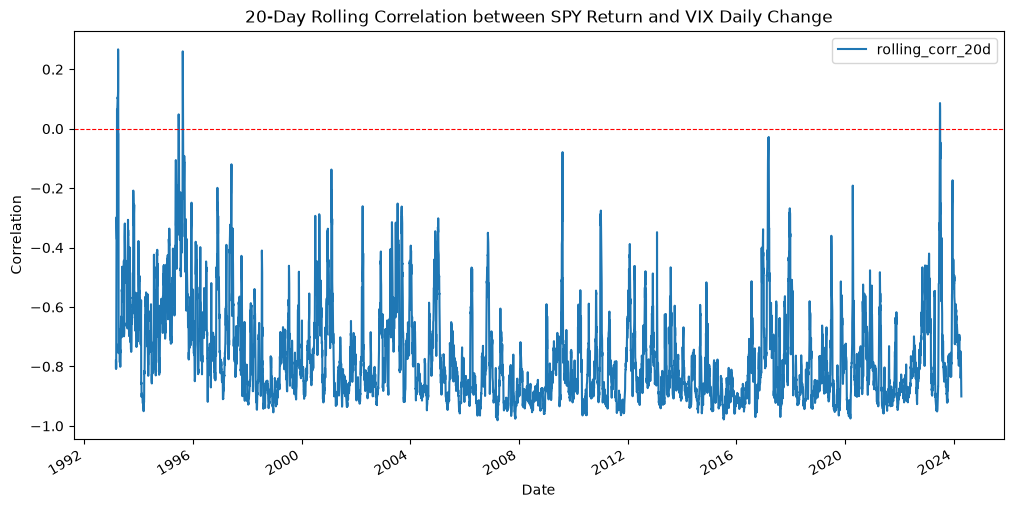

In [325]:
df_market['rolling_corr_20d'] = df_market['return'].rolling(window=20).corr(df_market['vix_daily_return'])
df_market.plot(x='date', y='rolling_corr_20d', figsize=(12, 6))
plt.title('20-Day Rolling Correlation between SPY Return and VIX Daily Change')
plt.axhline(0, color='red', linestyle='--', linewidth=0.8)
plt.xlabel('Date')
plt.ylabel('Correlation')
plt.show()

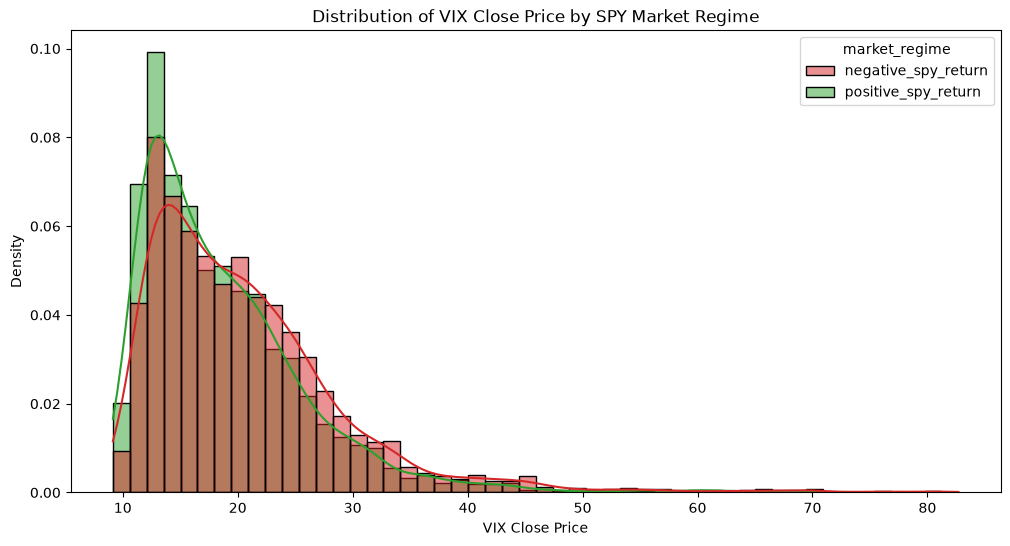

In [326]:
import seaborn as sns

df_market['market_regime'] = np.where(
    df_market['return'] >=0, 'positive_spy_return', 'negative_spy_return'
)
plt.figure(figsize=(12, 6))
sns.histplot(data=df_market, x='vix_close', hue='market_regime', bins=50,
              stat='density', common_norm=False, alpha=0.5,
              kde=True, palette={'positive_spy_return': '#2ca02c', 'negative_spy_return': '#d62728'})
plt.title('Distribution of VIX Close Price by SPY Market Regime')
plt.xlabel('VIX Close Price')
plt.ylabel('Density')
plt.show()

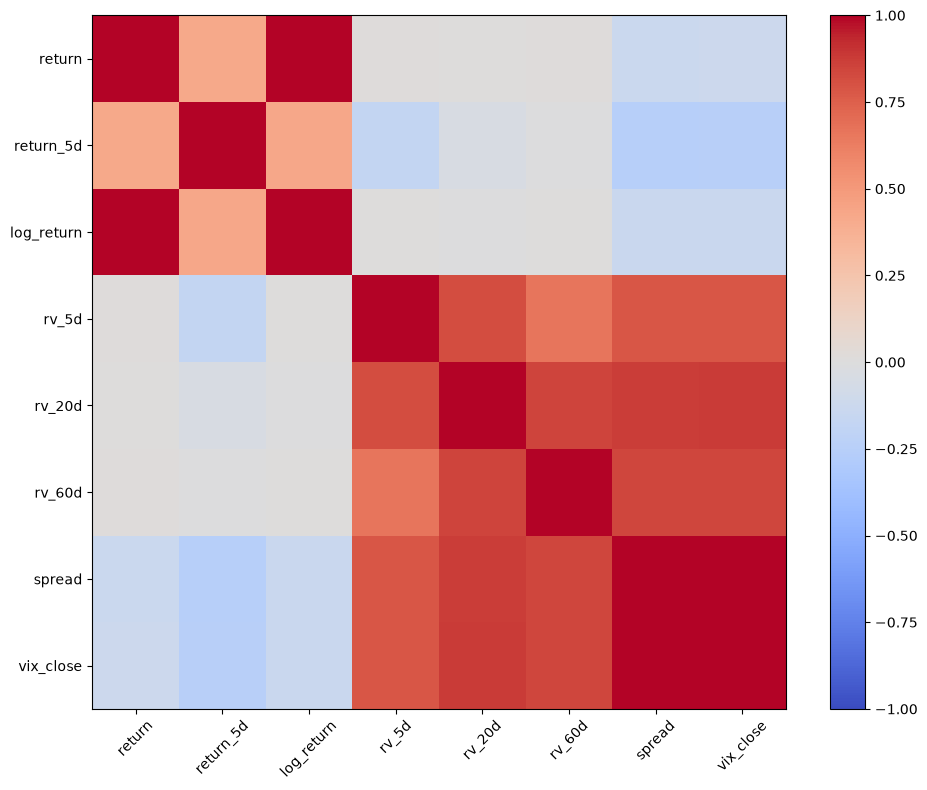

In [327]:
features = ['return', 'return_5d', 'log_return','rv_5d', 'rv_20d', 'rv_60d',
            'spread', 'vix_close']

corr = df_market[features].corr()
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(features)), features, rotation=45)
plt.yticks(range(len(features)), features)
plt.tight_layout()
plt.show()

In [328]:
calls = df_spy_opt[df_spy_opt['[UNDERLYING_LAST]'] < df_spy_opt['[STRIKE]']]
puts = df_spy_opt[df_spy_opt['[UNDERLYING_LAST]'] > df_spy_opt['[STRIKE]']]

calls = calls.drop(columns=['[P_DELTA]', '[P_GAMMA]', '[P_VEGA]',
                                '[P_THETA]', '[P_RHO]', '[P_IV]',
                                '[P_VOLUME]', '[P_LAST]', '[P_SIZE]', '[P_ASK]', '[P_BID]'])
calls = calls.rename(columns={'[C_DELTA]': '[DELTA]', '[C_GAMMA]': '[GAMMA]',
                                '[C_VEGA]': '[VEGA]', '[C_THETA]': '[THETA]', 
                                '[C_RHO]': '[RHO]', '[C_IV]': '[IV]', 
                                '[C_VOLUME]': '[VOLUME]', '[C_LAST]': '[LAST]', 
                                '[C_SIZE]': '[SIZE]', '[C_ASK]': '[ASK]', '[C_BID]': '[BID]'})
puts = puts.drop(columns=['[C_DELTA]', '[C_GAMMA]', '[C_VEGA]',
                                    '[C_THETA]', '[C_RHO]', '[C_IV]',
                                    '[C_VOLUME]', '[C_LAST]', '[C_SIZE]', '[C_ASK]', '[C_BID]'])
puts = puts.rename(columns={'[P_DELTA]': '[DELTA]', '[P_GAMMA]': '[GAMMA]',
                            '[P_VEGA]': '[VEGA]', '[P_THETA]': '[THETA]', 
                            '[P_RHO]': '[RHO]', '[P_IV]': '[IV]', 
                            '[P_VOLUME]': '[VOLUME]', '[P_LAST]': '[LAST]', 
                            '[P_SIZE]': '[SIZE]', '[P_ASK]': '[ASK]', '[P_BID]': '[BID]'})

In [329]:
df_options = pd.merge(calls, puts, how='outer')
print(df_options.head())    

   [QUOTE_UNIXTIME]  [QUOTE_READTIME] [QUOTE_DATE]  [QUOTE_TIME_HOURS]  \
0        1262638800  2010-01-04 16:00   2010-01-04                16.0   
1        1262638800  2010-01-04 16:00   2010-01-04                16.0   
2        1262638800  2010-01-04 16:00   2010-01-04                16.0   
3        1262638800  2010-01-04 16:00   2010-01-04                16.0   
4        1262638800  2010-01-04 16:00   2010-01-04                16.0   

   [UNDERLYING_LAST] [EXPIRE_DATE]  [EXPIRE_UNIX]  [DTE]  [DELTA]  [GAMMA]  \
0             113.29    2010-01-15     1263589200   11.0 -0.46613  0.12400   
1             113.29    2010-01-15     1263589200   11.0 -0.35394  0.10826   
2             113.29    2010-01-15     1263589200   11.0 -0.26336  0.08932   
3             113.29    2010-01-15     1263589200   11.0 -0.19484  0.07090   
4             113.29    2010-01-15     1263589200   11.0 -0.14489  0.05490   

   ...    [RHO]     [IV]  [VOLUME]  [LAST]      [SIZE]  [BID] [ASK]  [STRIKE]  \
0  ..

In [339]:
df_spy_opt['[QUOTE_READTIME]'] = pd.to_datetime(df_spy_opt['[QUOTE_READTIME]'], format='%Y-%m-%d %H:%M')
df_spy_opt['[EXPIRE_DATE]'] = pd.to_datetime(df_spy_opt['[EXPIRE_DATE]'], format='%Y-%m-%d')
df_spy_opt['log_moneyness'] = np.log(df_spy_opt['[STRIKE]'] / df_spy_opt['[UNDERLYING_LAST]'])

In [340]:
def inspect_options_data(df):

    print("=" * 50)
    print("OPTIONS DATA QUALITY REPORT")
    print("=" * 50)

    print(f"Total observations: {len(df):,}")

    if '[QUOTE_READTIME]' in df.columns:
        dates = pd.to_datetime(df['[QUOTE_READTIME]'])
        print(f"Unique dates: {dates.dt.date.nunique():,}")
        print(f"Date range: {dates.min()} to {dates.max()}")

    if '[EXPIRE_DATE]' in df.columns:
        print(
            f"Unique expirations: "
            f"{df['[EXPIRE_DATE]'].nunique():,}"
        )

    print("\nMissing values:")
    print(df.isna().sum().sort_values(ascending=False))

    if 'iv' in df.columns:
        iv = pd.to_numeric(df['[IV]'], errors='coerce')

        print("\nIV Statistics:")
        print(iv.describe())

        print(f"Invalid IV: {(iv <= 0).sum():,}")
        print(f"Missing IV: {iv.isna().sum():,}")

    if '[DTE]' in df.columns:
        print("\nDTE Distribution:")
        print(
            pd.to_numeric(df['[DTE]'], errors='coerce')
            .describe()
        )

    if '[STRIKE]' in df.columns:
        print(
            f"\nUnique strikes: {df['[STRIKE]'].nunique():,}"
        )

    print("=" * 50)

In [341]:
inspect_options_data(df_options)

OPTIONS DATA QUALITY REPORT
Total observations: 8,495,407
Unique dates: 3,258
Date range: 2010-01-04 16:00:00 to 2022-12-30 16:00:00
Unique expirations: 1,317

Missing values:
[VOLUME]                 2263654
[ASK]                      11654
[BID]                      11654
[LAST]                     11648
[IV]                        1823
[THETA]                     1779
[DELTA]                     1779
[GAMMA]                     1779
[VEGA]                      1779
[RHO]                       1779
[STRIKE_DISTANCE_PCT]          0
[STRIKE_DISTANCE]              0
[STRIKE]                       0
[SIZE]                         0
[QUOTE_UNIXTIME]               0
[QUOTE_READTIME]               0
[DTE]                          0
[EXPIRE_UNIX]                  0
[EXPIRE_DATE]                  0
[UNDERLYING_LAST]              0
[QUOTE_TIME_HOURS]             0
[QUOTE_DATE]                   0
log_moneyness                  0
dtype: int64

DTE Distribution:
count    8.495407e+06
mean     1.

In [342]:
import pandas as pd
import numpy as np

def preprocess_options(df):

    df = df.copy()

    # Convert dates
    date_cols = [
        '[QUOTE_READTIME]',
        '[QUOTE_DATE]',
        '[EXPIRE_DATE]'
    ]

    for col in date_cols:
        df[col] = pd.to_datetime(df[col], errors='coerce')

    # Convert numeric columns
    numeric_cols = [
        '[UNDERLYING_LAST]',
        '[STRIKE]',
        '[DTE]',
        '[DELTA]',
        '[GAMMA]',
        '[VEGA]',
        '[THETA]',
        '[RHO]',
        '[IV]',
        '[VOLUME]',
        '[LAST]',
        '[BID]',
        '[ASK]'
    ]

    for col in numeric_cols:
        df[col] = pd.to_numeric(
            df[col],
            errors='coerce'
        )

    # Remove observations missing essential information
    df = df.dropna(subset=[
        '[QUOTE_READTIME]',
        '[EXPIRE_DATE]',
        '[UNDERLYING_LAST]',
        '[STRIKE]',
        '[DTE]',
        '[DELTA]',
        '[IV]'
    ])

    # Remove fundamentally invalid observations
    df = df[
        (df['[UNDERLYING_LAST]'] > 0) &
        (df['[STRIKE]'] > 0) &
        (df['[DTE]'] > 0) &
        (df['[IV]'] > 0) &
        (df['[IV]'] < 5) &
        (df['[DELTA]'].abs() <= 1)
    ].copy()

    # Calculate log-moneyness
    df['log_moneyness'] = np.log(
        df['[STRIKE]'] / df['[UNDERLYING_LAST]']
    )

    # Identify option type
    df['option_type'] = np.where(
        df['[DELTA]'] > 0,
        'call',
        'put'
    )

    # Identify OTM options
    df['is_otm'] = (
        ((df['option_type'] == 'call') &
         (df['[STRIKE]'] >= df['[UNDERLYING_LAST]'])) |
        ((df['option_type'] == 'put') &
         (df['[STRIKE]'] <= df['[UNDERLYING_LAST]']))
    )

    # Calculate bid-ask statistics
    df['mid_price'] = (
        df['[BID]'] + df['[ASK]']
    ) / 2

    df['bid_ask_spread'] = (
        df['[ASK]'] - df['[BID]']
    )

    df['relative_spread'] = (
        df['bid_ask_spread'] / df['mid_price']
    ).replace([np.inf, -np.inf], np.nan)

    # Basic quote quality
    df['valid_quote'] = (
        (df['[BID]'] > 0) &
        (df['[ASK]'] >= df['[BID]']) &
        (df['mid_price'] > 0)
    )

    # Less aggressive quality filter
    df['good_quote'] = (
        df['valid_quote'] &
        (df['relative_spread'] <= 0.50)
    )

    # Historical date
    df['date'] = df['[QUOTE_DATE]'].dt.date

    return df

In [386]:
clean_df = preprocess_options(df_options)

print("Original observations:", len(df_options))
print("Processed observations:", len(clean_df))

print(
    clean_df['option_type'].value_counts()
)

print(
    clean_df['is_otm'].value_counts()
)

print(
    clean_df['good_quote'].value_counts()
)

Original observations: 8495407
Processed observations: 8350883
option_type
put     5159886
call    3190997
Name: count, dtype: int64
is_otm
True     8348786
False       2097
Name: count, dtype: int64
good_quote
True     6612313
False    1738570
Name: count, dtype: int64


In [387]:
snapshot_report = (
    clean_df.groupby('date')
    .agg(
        observations=('[QUOTE_READTIME]', 'size'),
        snapshots=('[QUOTE_READTIME]', 'nunique'),
        expirations=('[EXPIRE_DATE]', 'nunique'),
        strikes=('[STRIKE]', 'nunique'),
        underlying_price=('[UNDERLYING_LAST]', 'median')
    )
)

print(snapshot_report.describe())

       observations  snapshots  expirations      strikes  underlying_price
count   3258.000000     3258.0  3258.000000  3258.000000       3258.000000
mean    2563.193063        1.0    25.428791   229.747084        240.456172
std     1331.589201        0.0     7.466227    67.638684         98.716899
min      864.000000        1.0    12.000000   122.000000        102.250000
25%     1415.000000        1.0    18.000000   163.000000        156.762500
50%     2187.500000        1.0    24.000000   229.000000        212.690000
75%     3445.750000        1.0    33.000000   284.000000        293.440000
max     5812.000000        1.0    38.000000   393.000000        477.770000


In [388]:
print(snapshot_report.head(10))
print(snapshot_report.tail(10))

            observations  snapshots  expirations  strikes  underlying_price
date                                                                       
2010-01-04           914          1           13      131            113.29
2010-01-05           914          1           12      131            113.64
2010-01-06           996          1           13      131            113.74
2010-01-07           996          1           13      131            114.20
2010-01-08           996          1           13      131            114.54
2010-01-11           996          1           13      131            114.73
2010-01-12          1002          1           13      131            113.66
2010-01-13          1005          1           13      131            114.63
2010-01-14          1005          1           13      131            114.92
2010-01-15           895          1           12      131            113.66
            observations  snapshots  expirations  strikes  underlying_price
date        

In [389]:
clean_df['dte_bucket'] = pd.cut(
    clean_df['[DTE]'],
    bins=[0, 7, 14, 30, 60, 90, 180, 365, float('inf')],
    labels=[
        '0-7',
        '8-14',
        '15-30',
        '31-60',
        '61-90',
        '91-180',
        '181-365',
        '365+'
    ]
)

dte_report = (
    clean_df.groupby('dte_bucket', observed=False)
    .agg(
        observations=('[IV]', 'size'),
        median_iv=('[IV]', 'median'),
        median_spread=('relative_spread', 'median'),
        good_quote_pct=('good_quote', 'mean')
    )
)

dte_report['good_quote_pct'] *= 100

print(dte_report)

            observations  median_iv  median_spread  good_quote_pct
dte_bucket                                                        
0-7               676101    0.31300       0.666667       42.434340
8-14              618969    0.24718       0.105263       65.718477
15-30            1233501    0.21737       0.044944       78.533945
31-60            1053652    0.22054       0.036364       80.454173
61-90             555788    0.24004       0.029674       80.010184
91-180           1303785    0.22447       0.027290       85.197176
181-365          1628102    0.20765       0.035165       89.287895
365+             1280985    0.20260       0.094241       85.328087


In [390]:
year_report = (
    clean_df.groupby(
        clean_df['[QUOTE_DATE]'].dt.year
    )
    .agg(
        observations=('[IV]', 'size'),
        median_iv=('[IV]', 'median'),
        median_spread=('relative_spread', 'median'),
        good_quote_pct=('good_quote', 'mean')
    )
)

year_report['good_quote_pct'] *= 100

print(year_report)

              observations  median_iv  median_spread  good_quote_pct
[QUOTE_DATE]                                                        
2010                260870    0.27433       0.077922       68.033120
2011                282947    0.25734       0.061094       72.724927
2012                337911    0.23450       0.074074       69.944157
2013                355982    0.20185       0.089552       70.645988
2014                415496    0.19093       0.086957       71.464948
2015                485732    0.20320       0.081656       73.103275
2016                535406    0.19703       0.047619       73.749640
2017                599615    0.17656       0.050420       75.285642
2018                739868    0.19487       0.054054       79.274411
2019                818468    0.17613       0.032207       82.887052
2020               1143228    0.28084       0.040000       86.260658
2021               1255394    0.22575       0.037940       85.752839
2022               1119966    0.24

In [391]:
import numpy as np
import pandas as pd

def filter_surface_data(
    df,
    min_dte=7,
    max_dte=180,
    max_relative_spread=0.50,
    min_log_moneyness=-0.15,
    max_log_moneyness=0.15
):
    data = df.copy()

    # Require a valid, positive bid and a non-crossed market
    data = data[
        (data['[BID]'] > 0) &
        (data['[ASK]'] >= data['[BID]']) &
        (data['mid_price'] > 0)
    ].copy()

    # Require reasonable relative spreads
    data = data[
        (data['relative_spread'] >= 0) &
        (data['relative_spread'] <= max_relative_spread)
    ].copy()

    # Filter maturity
    data = data[
        data['[DTE]'].between(min_dte, max_dte)
    ].copy()

    # Filter moneyness
    data = data[
        data['log_moneyness'].between(
            min_log_moneyness,
            max_log_moneyness
        )
    ].copy()

    # Remove invalid IV values
    data = data[
        np.isfinite(data['[IV]']) &
        (data['[IV]'] > 0)
    ].copy()

    return data

In [392]:
surface_data = filter_surface_data(clean_df)

In [393]:
def construct_iv_surface(
    df,
    target_date,
    n_moneyness_bins=31
):
    # Select one trading date
    daily = df[
        df['[QUOTE_DATE]'].dt.date == pd.Timestamp(target_date).date()
    ].copy()

    if daily.empty:
        raise ValueError(f"No observations found for {target_date}")

    # Create fixed moneyness buckets
    bins = np.linspace(-0.15, 0.15, n_moneyness_bins + 1)

    daily['moneyness_bin'] = pd.cut(
        daily['log_moneyness'],
        bins=bins,
        labels=False,
        include_lowest=True
    )

    # Calculate the midpoint of each moneyness bucket
    daily['moneyness_mid'] = (
        -0.15 +
        (daily['moneyness_bin'] + 0.5)
        * (0.30 / n_moneyness_bins)
    )

    # Aggregate IV by maturity and moneyness
    surface = (
        daily.groupby(
            ['[DTE]', 'moneyness_mid'],
            observed=True
        )['[IV]']
        .median()
        .unstack()
        .sort_index()
    )

    return surface

In [394]:
surface = construct_iv_surface(
    surface_data,
    '2010-01-04'
)

print(surface)

moneyness_mid  -0.145161  -0.135484  -0.125806  -0.116129  -0.106452  \
[DTE]                                                                  
11.00            0.38896        NaN    0.35473    0.34214    0.32434   
46.00            0.27685    0.27031    0.26327    0.25510    0.24834   
73.96            0.27280    0.26813    0.26326    0.25734    0.25321   
85.96            0.26931    0.26456    0.25974    0.25502    0.24967   
164.96           0.26676    0.26137    0.25856    0.25419    0.24920   
176.96           0.26495    0.26118    0.25674    0.25318    0.25063   

moneyness_mid  -0.096774  -0.087097  -0.077419  -0.067742  -0.058065  ...  \
[DTE]                                                                 ...   
11.00            0.30485    0.28459    0.26740    0.24961    0.23312  ...   
46.00            0.24186    0.23414    0.22676    0.22056    0.21347  ...   
73.96            0.24630    0.24076    0.23448    0.23106    0.22505  ...   
85.96            0.24480    0.24001   

In [395]:
import plotly.graph_objects as go

def plot_iv_surface(surface, title="SPY Implied Volatility Surface"):

    x = surface.columns.to_numpy(dtype=float)
    y = surface.index.to_numpy(dtype=float)
    z = surface.to_numpy()

    fig = go.Figure(
        data=[
            go.Surface(
                x=x,
                y=y,
                z=z,
                colorscale='Viridis',
                colorbar=dict(title='IV')
            )
        ]
    )

    fig.update_layout(
        title=title,
        scene=dict(
            xaxis_title='Log Moneyness',
            yaxis_title='Days to Expiration',
            zaxis_title='Implied Volatility',
        ),
        width=1000,
        height=800
    )

    fig.show()

In [396]:
plot_iv_surface(surface)

In [397]:
total_cells = surface.size
observed_cells = surface.notna().sum().sum()

print("Total grid cells:", total_cells)
print("Observed grid cells:", observed_cells)

print(
    "Surface coverage:",
    round(100 * observed_cells / total_cells, 2),
    "%"
)

Total grid cells: 186
Observed grid cells: 159
Surface coverage: 85.48 %


In [398]:
n_bins = 31

all_moneyness_mid = (
    -0.15 +
    (np.arange(n_bins) + 0.5) * (0.30 / n_bins)
)

surface_full = surface.reindex(
    columns=all_moneyness_mid
)

print("Total grid cells:", surface_full.size)
print("Observed grid cells:", surface_full.notna().sum().sum())

print(
    "Surface coverage:",
    round(100 * surface_full.notna().sum().sum()
          / surface_full.size, 2),
    "%"
)

Total grid cells: 186
Observed grid cells: 159
Surface coverage: 85.48 %


In [399]:
def construct_iv_surface_with_counts(
    df,
    target_date,
    n_moneyness_bins=31
):
    daily = df[
        df['[QUOTE_DATE]'].dt.date ==
        pd.Timestamp(target_date).date()
    ].copy()

    bins = np.linspace(
        -0.15, 0.15, n_moneyness_bins + 1
    )

    daily['moneyness_bin'] = pd.cut(
        daily['log_moneyness'],
        bins=bins,
        labels=False,
        include_lowest=True
    )

    daily = daily.dropna(subset=['moneyness_bin'])

    daily['moneyness_mid'] = (
        -0.15 +
        (daily['moneyness_bin'] + 0.5)
        * (0.30 / n_moneyness_bins)
    )

    grouped = daily.groupby(
        ['[DTE]', 'moneyness_mid'],
        observed=True
    )['[IV]']

    iv_surface = grouped.median().unstack()

    count_surface = grouped.count().unstack()

    all_moneyness_mid = (
        -0.15 +
        (np.arange(n_moneyness_bins) + 0.5)
        * (0.30 / n_moneyness_bins)
    )

    iv_surface = iv_surface.reindex(
        columns=all_moneyness_mid
    )

    count_surface = count_surface.reindex(
        columns=all_moneyness_mid
    ).fillna(0)

    return iv_surface, count_surface

In [400]:
iv_surface, count_surface = construct_iv_surface_with_counts(
    surface_data,
    '2010-01-04'
)

print(count_surface)
print("\nObservations per nonempty cell:")
print(count_surface.stack().describe())

moneyness_mid  -0.145161  -0.135484  -0.125806  -0.116129  -0.106452  \
[DTE]                                                                  
11.00                1.0        0.0        1.0        1.0        1.0   
46.00                1.0        1.0        1.0        1.0        1.0   
73.96                1.0        1.0        1.0        1.0        1.0   
85.96                1.0        1.0        1.0        1.0        1.0   
164.96               1.0        1.0        1.0        1.0        1.0   
176.96               1.0        1.0        1.0        1.0        1.0   

moneyness_mid  -0.096774  -0.087097  -0.077419  -0.067742  -0.058065  ...  \
[DTE]                                                                 ...   
11.00                1.0        1.0        1.0        1.0        1.0  ...   
46.00                1.0        1.0        1.0        1.0        1.0  ...   
73.96                1.0        1.0        1.0        1.0        1.0  ...   
85.96                1.0        1.0   

In [401]:
import plotly.express as px

fig = px.imshow(
    count_surface,
    labels=dict(
        x="Log Moneyness",
        y="DTE",
        color="Number of Options"
    ),
    title="Option Observations Supporting Each IV Surface Cell",
    aspect="auto",
    color_continuous_scale="Viridis"
)

fig.show()

In [402]:
import plotly.express as px

daily = surface_data[
    surface_data['[QUOTE_DATE]'].dt.date ==
    pd.Timestamp('2010-01-04').date()
].copy()

selected_dte = 46

smile = daily[
    daily['[DTE]'] == selected_dte
].sort_values('log_moneyness')

fig = px.scatter(
    smile,
    x='log_moneyness',
    y='[IV]',
    color='option_type',
    title=f'IV Smile: January 4, 2010 ({selected_dte} DTE)',
    labels={
        'log_moneyness': 'Log Moneyness',
        '[IV]': 'Implied Volatility',
        'option_type': 'Option Type'
    }
)

fig.show()

In [403]:
def construct_binned_iv_surface(
    df,
    target_date,
    n_moneyness_bins=11
):
    daily = df[
        df['[QUOTE_DATE]'].dt.date ==
        pd.Timestamp(target_date).date()
    ].copy()

    daily['maturity_bucket'] = pd.cut(
        daily['[DTE]'],
        bins=[7, 14, 30, 60, 90, 180],
        labels=[
            '7-14',
            '15-30',
            '31-60',
            '61-90',
            '91-180'
        ],
        include_lowest=True
    )

    bins = np.linspace(-0.15, 0.15, n_moneyness_bins + 1)

    daily['moneyness_bin'] = pd.cut(
        daily['log_moneyness'],
        bins=bins,
        labels=False,
        include_lowest=True
    )

    surface = (
        daily.groupby(
            ['maturity_bucket', 'moneyness_bin'],
            observed=True
        )['[IV]']
        .median()
        .unstack()
    )

    return surface

In [404]:
binned_surface = construct_binned_iv_surface(
    surface_data,
    '2010-01-04'
)

print(binned_surface)

moneyness_bin          0         1         2         3         4         5   \
maturity_bucket                                                               
7-14             0.371845  0.333240  0.284590  0.233120  0.189490  0.156050   
31-60            0.270310  0.251720  0.234140  0.213470  0.194550  0.175700   
61-90            0.266345  0.254115  0.240385  0.224795  0.210290  0.196710   
91-180           0.261275  0.251905  0.242665  0.231960  0.222315  0.212595   

moneyness_bin          6        7        8         9        10  
maturity_bucket                                                 
7-14             0.147370  0.16943  0.19376       NaN      NaN  
31-60            0.165710  0.15155  0.14840  0.145310      NaN  
61-90            0.184355  0.17061  0.16099  0.154555  0.15224  
91-180           0.204275  0.19411  0.18484  0.176890  0.16895  


In [405]:
import numpy as np
import pandas as pd

def interpolate_iv_by_delta(
    options,
    target_delta,
    max_delta_gap=0.15
):

    data = options[['[DELTA]', '[IV]']].copy()

    data = data.dropna()

    data = data[
        np.isfinite(data['[DELTA]']) &
        np.isfinite(data['[IV]'])
    ]

    # Combine duplicate delta values
    data = (
        data.groupby('[DELTA]', as_index=False)['[IV]']
        .median()
        .sort_values('[DELTA]')
    )

    if len(data) < 2:
        return np.nan

    x = data['[DELTA]'].to_numpy()
    y = data['[IV]'].to_numpy()

    # Do not extrapolate
    if target_delta < x.min() or target_delta > x.max():
        return np.nan

    # Find the two observations surrounding target_delta
    idx = np.searchsorted(x, target_delta)

    if idx < len(x) and np.isclose(x[idx], target_delta):
        return float(y[idx])

    if idx == 0 or idx == len(x):
        return np.nan

    x_left, x_right = x[idx - 1], x[idx]

    if x_right - x_left > max_delta_gap:
        return np.nan

    return float(
        np.interp(target_delta, x, y)
    )

In [406]:
def interpolate_atm_iv(
    options,
    max_moneyness_gap=0.04
):
    """
    Estimate ATM IV by interpolating across
    log-moneyness zero.
    """

    data = options[
        ['log_moneyness', '[IV]']
    ].dropna().copy()

    data = (
        data.groupby('log_moneyness', as_index=False)['[IV]']
        .median()
        .sort_values('log_moneyness')
    )

    if len(data) < 2:
        return np.nan

    x = data['log_moneyness'].to_numpy()
    y = data['[IV]'].to_numpy()

    # If an exact ATM observation exists
    exact = np.where(np.isclose(x, 0, atol=1e-10))[0]

    if len(exact) > 0:
        return float(y[exact[0]])

    left = np.where(x < 0)[0]
    right = np.where(x > 0)[0]

    if len(left) == 0 or len(right) == 0:
        return np.nan

    left_idx = left[-1]
    right_idx = right[0]

    if x[right_idx] - x[left_idx] > max_moneyness_gap:
        return np.nan

    return float(
        np.interp(
            0,
            [x[left_idx], x[right_idx]],
            [y[left_idx], y[right_idx]]
        )
    )

In [407]:
def extract_expiration_features(options):
    """
    Extract volatility-surface features for
    one trading date and one expiration.
    """

    options = options.copy()

    # Keep OTM options
    options = options[options['is_otm']].copy()

    # Identify calls and puts
    puts = options[
        (options['[DELTA]'] < 0) &
        (options['log_moneyness'] < 0)
    ]

    calls = options[
        (options['[DELTA]'] > 0) &
        (options['log_moneyness'] > 0)
    ]

    # ATM volatility
    atm_iv = interpolate_atm_iv(options)

    # 25-delta volatilities
    put_25_iv = interpolate_iv_by_delta(
        puts,
        target_delta=-0.25
    )

    call_25_iv = interpolate_iv_by_delta(
        calls,
        target_delta=0.25
    )

    # Risk reversal
    rr_25 = (
        call_25_iv - put_25_iv
        if np.isfinite(call_25_iv) and np.isfinite(put_25_iv)
        else np.nan
    )

    # Butterfly
    bf_25 = (
        (call_25_iv + put_25_iv) / 2 - atm_iv
        if all(np.isfinite([
            call_25_iv,
            put_25_iv,
            atm_iv
        ]))
        else np.nan
    )

    return pd.Series({
        'date': options['[QUOTE_DATE]'].iloc[0],
        'expiration': options['[EXPIRE_DATE]'].iloc[0],
        'dte': options['[DTE]'].median(),
        'atm_iv': atm_iv,
        'put_25_iv': put_25_iv,
        'call_25_iv': call_25_iv,
        'rr_25': rr_25,
        'bf_25': bf_25,
        'n_options': len(options),
        'n_puts': len(puts),
        'n_calls': len(calls)
    })

In [408]:
daily = surface_data[
    surface_data['[QUOTE_DATE]'].dt.date ==
    pd.Timestamp('2010-01-04').date()
].copy()

daily_features = pd.DataFrame([
    extract_expiration_features(group)
    for _, group in daily.groupby('[EXPIRE_DATE]')
])

print(
    daily_features
)

        date expiration     dte    atm_iv  put_25_iv  call_25_iv     rr_25  \
0 2010-01-04 2010-01-15   11.00  0.155692   0.180667    0.148146 -0.032521   
1 2010-01-04 2010-02-19   46.00  0.175438   0.207505    0.158403 -0.049101   
2 2010-01-04 2010-03-19   73.96  0.196327   0.231788    0.171583 -0.060205   
3 2010-01-04 2010-03-31   85.96  0.196562   0.233751    0.171999 -0.061752   
4 2010-01-04 2010-06-18  164.96  0.212472   0.249960    0.184558 -0.065403   
5 2010-01-04 2010-06-30  176.96  0.211951   0.252009         NaN       NaN   

      bf_25  n_options  n_puts  n_calls  
0  0.008714         23      15        8  
1  0.007516         27      16       11  
2  0.005359         32      16       16  
3  0.006313         33      16       17  
4  0.004787         34      16       18  
5       NaN         23      16        7  


In [409]:
feature_cols = [
    'atm_iv',
    'put_25_iv',
    'call_25_iv',
    'rr_25',
    'bf_25'
]

coverage = (
    daily_features[feature_cols]
    .notna()
    .mean()
    .mul(100)
)

print("Feature coverage (%):")
print(coverage)

Feature coverage (%):
atm_iv        100.000000
put_25_iv     100.000000
call_25_iv     83.333333
rr_25          83.333333
bf_25          83.333333
dtype: float64


In [410]:
print(
    daily_features[
        feature_cols + ['dte', 'n_options']
    ].describe()
)

         atm_iv  put_25_iv  call_25_iv     rr_25     bf_25         dte  \
count  6.000000   6.000000    5.000000  5.000000  5.000000    6.000000   
mean   0.191407   0.225947    0.166938 -0.053796  0.006538   93.140000   
std    0.022123   0.027354    0.013997  0.013358  0.001597   65.684837   
min    0.155692   0.180667    0.148146 -0.065403  0.004787   11.000000   
25%    0.180660   0.213576    0.158403 -0.061752  0.005359   52.990000   
50%    0.196444   0.232770    0.171583 -0.060205  0.006313   79.960000   
75%    0.208103   0.245908    0.171999 -0.049101  0.007516  145.210000   
max    0.212472   0.252009    0.184558 -0.032521  0.008714  176.960000   

       n_options  
count   6.000000  
mean   28.666667  
std     5.006662  
min    23.000000  
25%    24.000000  
50%    29.500000  
75%    32.750000  
max    34.000000  


In [411]:
import numpy as np
import pandas as pd

def interpolate_constant_maturity(
    expiration_features,
    target_dte,
    iv_column,
    max_bracket_width=90
):

    data = expiration_features[
        ['dte', iv_column]
    ].dropna().copy()

    data = data[
        np.isfinite(data['dte']) &
        np.isfinite(data[iv_column]) &
        (data['dte'] > 0) &
        (data[iv_column] > 0)
    ]

    data = (
        data.groupby('dte', as_index=False)[iv_column]
        .median()
        .sort_values('dte')
    )

    if data.empty:
        return np.nan, np.nan, np.nan

    dte = data['dte'].to_numpy(dtype=float)
    iv = data[iv_column].to_numpy(dtype=float)

    # Exact maturity
    exact = np.where(np.isclose(dte, target_dte))[0]

    if len(exact):
        i = exact[0]
        return float(iv[i]), float(dte[i]), float(dte[i])

    # No extrapolation
    if target_dte < dte.min() or target_dte > dte.max():
        return np.nan, np.nan, np.nan

    right = np.searchsorted(dte, target_dte)
    left = right - 1

    t1, t2 = dte[left], dte[right]
    sigma1, sigma2 = iv[left], iv[right]

    if t2 - t1 > max_bracket_width:
        return np.nan, t1, t2

    # Total implied variance
    w1 = sigma1**2 * (t1 / 365)
    w2 = sigma2**2 * (t2 / 365)

    weight = (target_dte - t1) / (t2 - t1)

    w_target = w1 + weight * (w2 - w1)

    if w_target <= 0:
        return np.nan, t1, t2

    iv_target = np.sqrt(
        w_target / (target_dte / 365)
    )

    return float(iv_target), float(t1), float(t2)

In [412]:
for target in [14, 30, 60, 90]:
    iv, lower, upper = interpolate_constant_maturity(
        daily_features,
        target_dte=target,
        iv_column='atm_iv'
    )

    print(
        f"{target}D ATM IV: {iv:.4%} "
        f"(using {lower:.2f}D and {upper:.2f}D)"
    )

14D ATM IV: 16.1498% (using 11.00D and 46.00D)
30D ATM IV: 17.2286% (using 11.00D and 46.00D)
60D ATM IV: 18.8604% (using 46.00D and 73.96D)
90D ATM IV: 19.8107% (using 85.96D and 164.96D)


In [413]:
def extract_constant_maturity_features(
    expiration_features,
    target_maturities=(14, 30, 60, 90)
):
    result = {
        'date': expiration_features['date'].iloc[0]
    }

    iv_columns = ['atm_iv', 'put_25_iv', 'call_25_iv']

    for maturity in target_maturities:

        for column in iv_columns:
            iv, lower, upper = interpolate_constant_maturity(
                expiration_features,
                target_dte=maturity,
                iv_column=column
            )

            result[f'{column}_{maturity}d'] = iv

            result[f'{column}_{maturity}d_bracket_width'] = (
                upper - lower
                if np.isfinite(lower) and np.isfinite(upper)
                else np.nan
            )

        atm = result[f'atm_iv_{maturity}d']
        put = result[f'put_25_iv_{maturity}d']
        call = result[f'call_25_iv_{maturity}d']

        if np.isfinite(put) and np.isfinite(call):
            result[f'rr_25_{maturity}d'] = call - put
        else:
            result[f'rr_25_{maturity}d'] = np.nan

        if all(np.isfinite([atm, put, call])):
            result[f'bf_25_{maturity}d'] = (
                (call + put) / 2 - atm
            )
        else:
            result[f'bf_25_{maturity}d'] = np.nan

    return pd.Series(result)

In [414]:
daily_constant_features = extract_constant_maturity_features(
    daily_features
)

print(daily_constant_features.to_string())

date                            2010-01-04 00:00:00
atm_iv_14d                                 0.161498
atm_iv_14d_bracket_width                       35.0
put_25_iv_14d                              0.188612
put_25_iv_14d_bracket_width                    35.0
call_25_iv_14d                             0.151105
call_25_iv_14d_bracket_width                   35.0
rr_25_14d                                 -0.037507
bf_25_14d                                  0.008361
atm_iv_30d                                 0.172286
atm_iv_30d_bracket_width                       35.0
put_25_iv_30d                              0.203254
put_25_iv_30d_bracket_width                    35.0
call_25_iv_30d                             0.156731
call_25_iv_30d_bracket_width                   35.0
rr_25_30d                                 -0.046523
bf_25_30d                                  0.007706
atm_iv_60d                                 0.188604
atm_iv_60d_bracket_width                      27.96
put_25_iv_60

In [415]:
expiration_features = pd.DataFrame([
    extract_expiration_features(group)
    for _, group in surface_data.groupby(
        ['[QUOTE_DATE]', '[EXPIRE_DATE]'],
        sort=True
    )
])

print(expiration_features.shape)
print(expiration_features.head())

(45075, 11)
        date expiration     dte    atm_iv  put_25_iv  call_25_iv     rr_25  \
0 2010-01-04 2010-01-15   11.00  0.155692   0.180667    0.148146 -0.032521   
1 2010-01-04 2010-02-19   46.00  0.175438   0.207505    0.158403 -0.049101   
2 2010-01-04 2010-03-19   73.96  0.196327   0.231788    0.171583 -0.060205   
3 2010-01-04 2010-03-31   85.96  0.196562   0.233751    0.171999 -0.061752   
4 2010-01-04 2010-06-18  164.96  0.212472   0.249960    0.184558 -0.065403   

      bf_25  n_options  n_puts  n_calls  
0  0.008714         23      15        8  
1  0.007516         27      16       11  
2  0.005359         32      16       16  
3  0.006313         33      16       17  
4  0.004787         34      16       18  


In [416]:
daily_iv_features = pd.DataFrame([
    extract_constant_maturity_features(group)
    for _, group in expiration_features.groupby('date', sort=True)
])

daily_iv_features = (
    daily_iv_features
    .sort_values('date')
    .reset_index(drop=True)
)

print(daily_iv_features.shape)
print(daily_iv_features.head())

(3250, 33)
        date  atm_iv_14d  atm_iv_14d_bracket_width  put_25_iv_14d  \
0 2010-01-04    0.161498                      35.0       0.188612   
1 2010-01-05    0.157179                      35.0            NaN   
2 2010-01-06    0.159430                      35.0       0.183370   
3 2010-01-07    0.160413                      35.0            NaN   
4 2010-01-08    0.152139                      35.0       0.173968   

   put_25_iv_14d_bracket_width  call_25_iv_14d  call_25_iv_14d_bracket_width  \
0                         35.0        0.151105                          35.0   
1                          NaN        0.143559                          35.0   
2                         35.0        0.146423                          35.0   
3                          NaN        0.148463                          35.0   
4                         35.0        0.141139                          35.0   

   rr_25_14d  bf_25_14d  atm_iv_30d  ...  rr_25_60d  bf_25_60d  atm_iv_90d  \
0  -0.037507   

In [417]:
iv_feature_cols = [
    col for col in daily_iv_features.columns
    if (
        col.startswith(('atm_iv_', 'put_25_iv_', 'call_25_iv_',
                        'rr_25_', 'bf_25_'))
        and not col.endswith('_bracket_width')
    )
]

coverage = (
    daily_iv_features[iv_feature_cols]
    .notna()
    .mean()
    .mul(100)
    .sort_values()
)

print(coverage)

rr_25_14d          87.507692
bf_25_14d          87.507692
call_25_iv_14d     87.753846
put_25_iv_14d      89.876923
atm_iv_14d         90.184615
bf_25_30d          96.338462
rr_25_30d          96.369231
call_25_iv_30d     96.492308
put_25_iv_30d      97.600000
rr_25_90d          97.692308
atm_iv_30d         97.692308
bf_25_90d          97.692308
call_25_iv_90d     98.030769
rr_25_60d          98.461538
bf_25_60d          98.461538
call_25_iv_60d     98.615385
put_25_iv_90d      99.507692
put_25_iv_60d      99.723077
atm_iv_60d        100.000000
atm_iv_90d        100.000000
dtype: float64


In [418]:
original_dates = pd.DatetimeIndex(
    clean_df['[QUOTE_DATE]'].dropna().unique()
)

feature_dates = pd.DatetimeIndex(
    daily_iv_features['date'].dropna().unique()
)

missing_dates = original_dates.difference(feature_dates)

print("Missing dates:", len(missing_dates))
print(missing_dates)

Missing dates: 8
DatetimeIndex(['2010-01-27', '2010-01-28', '2010-01-29', '2010-02-01',
               '2010-02-02', '2010-02-03', '2010-02-04', '2010-02-05'],
              dtype='datetime64[us]', freq=None)


In [419]:
all_dates = pd.DataFrame({
    'date': pd.to_datetime(
        clean_df['[QUOTE_DATE]'].dropna().unique()
    )
})

daily_iv_features['date'] = pd.to_datetime(
    daily_iv_features['date']
)

daily_iv_features = (
    all_dates
    .merge(daily_iv_features, on='date', how='left')
    .sort_values('date')
    .reset_index(drop=True)
)

print(daily_iv_features.shape)

(3258, 33)


In [420]:
print(df_market.info())

<class 'pandas.DataFrame'>
Index: 7820 entries, 0 to 7853
Data columns (total 40 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   date                7820 non-null   datetime64[us]
 1   spy_open            7820 non-null   float64       
 2   spy_high            7820 non-null   float64       
 3   spy_low             7820 non-null   float64       
 4   spy_close           7820 non-null   float64       
 5   spy_volume          7820 non-null   int64         
 6   spy_adj_close       7820 non-null   float64       
 7   spy_change_percent  7819 non-null   float64       
 8   spy_avg_vol_20d     7801 non-null   float64       
 9   vix_open            7820 non-null   float64       
 10  vix_high            7820 non-null   float64       
 11  vix_low             7820 non-null   float64       
 12  vix_close           7820 non-null   float64       
 13  return              7819 non-null   float64       
 14  log_retu

In [421]:
print(daily_iv_features.info())

<class 'pandas.DataFrame'>
RangeIndex: 3258 entries, 0 to 3257
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   date                          3258 non-null   datetime64[us]
 1   atm_iv_14d                    2931 non-null   float64       
 2   atm_iv_14d_bracket_width      2931 non-null   float64       
 3   put_25_iv_14d                 2921 non-null   float64       
 4   put_25_iv_14d_bracket_width   2921 non-null   float64       
 5   call_25_iv_14d                2852 non-null   float64       
 6   call_25_iv_14d_bracket_width  2855 non-null   float64       
 7   rr_25_14d                     2844 non-null   float64       
 8   bf_25_14d                     2844 non-null   float64       
 9   atm_iv_30d                    3175 non-null   float64       
 10  atm_iv_30d_bracket_width      3175 non-null   float64       
 11  put_25_iv_30d                 3172 non-nu

In [422]:
df_model = df_market.merge(
    daily_iv_features,
    on='date',
    how='right',
    validate='one_to_one',
    indicator=True
)
print(df_model['_merge'].value_counts())

df_model = (
    df_model.drop(columns='_merge')
    .sort_values('date')
    .reset_index(drop=True)
)

print(df_model.shape)

_merge
both          3246
right_only      12
left_only        0
Name: count, dtype: int64
(3258, 72)


In [423]:
print(df_model.info())

<class 'pandas.DataFrame'>
RangeIndex: 3258 entries, 0 to 3257
Data columns (total 72 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   date                          3258 non-null   datetime64[us]
 1   spy_open                      3246 non-null   float64       
 2   spy_high                      3246 non-null   float64       
 3   spy_low                       3246 non-null   float64       
 4   spy_close                     3246 non-null   float64       
 5   spy_volume                    3246 non-null   float64       
 6   spy_adj_close                 3246 non-null   float64       
 7   spy_change_percent            3246 non-null   float64       
 8   spy_avg_vol_20d               3246 non-null   float64       
 9   vix_open                      3246 non-null   float64       
 10  vix_high                      3246 non-null   float64       
 11  vix_low                       3246 non-nu

In [424]:
df_model['atm_term_slope_30_90'] = (
    df_model['atm_iv_90d'] - df_model['atm_iv_30d']
)

df_model['atm_iv_30d_change_5d'] = (
    df_model['atm_iv_30d'] - df_model['atm_iv_30d'].shift(5)
)

In [425]:
def add_future_vol_targets(df, horizons=(5,20)):
    temp = df.copy().sort_values('date')

    r2 = temp['log_return'].pow(2)

    for h in horizons:
        future_squared_return = pd.concat(
            [
                r2.shift(-i)
                for i in range(1, h+1)
            ],
            axis=1
        )

        future_var = (
            252 * 
            future_squared_return.mean(
                axis=1,
                skipna=False
            )
        )

        temp[f'future_rv_{h}d'] = np.sqrt(future_var)

    return temp

In [432]:
df_model = add_future_vol_targets(df=df_model)

In [433]:
df_model.to_csv('../data/preprocessed/model_data.csv', index=False)

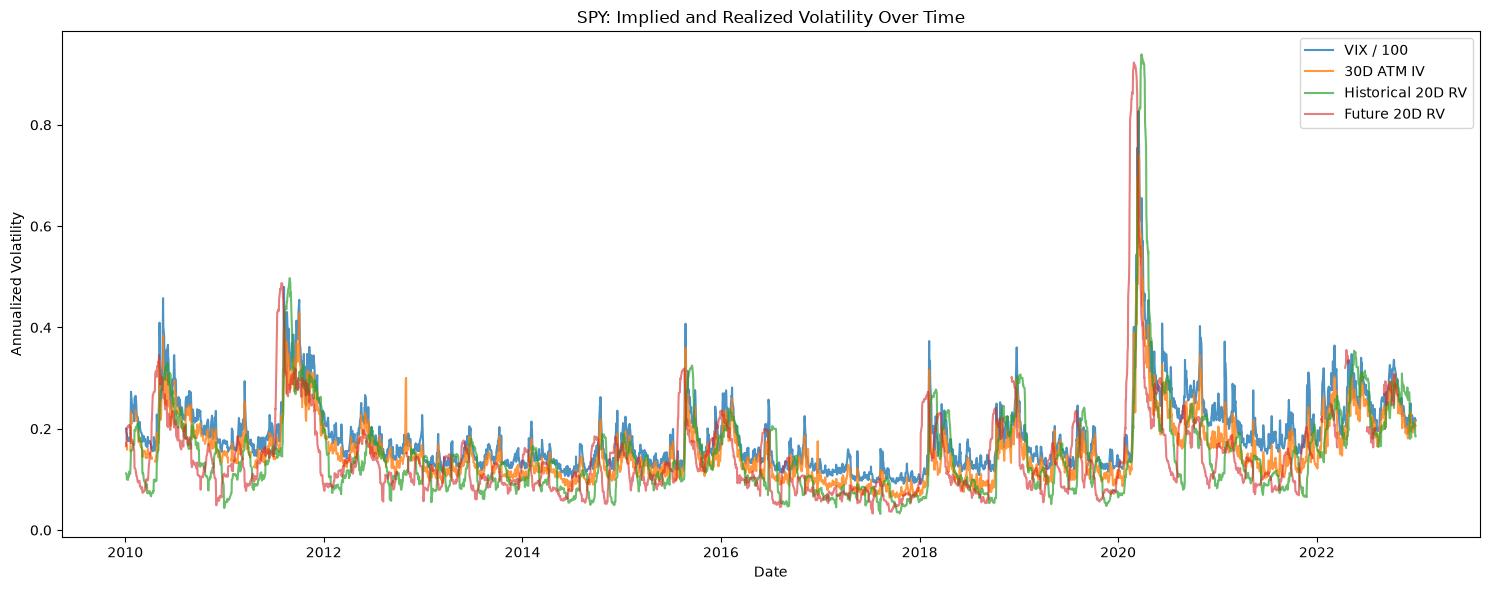

In [434]:
import matplotlib.pyplot as plt
import seaborn as sns

eda = df_model.copy()
eda['date'] = pd.to_datetime(eda['date'])
eda = eda.sort_values('date').reset_index(drop=True)

eda['vix_decimal'] = eda['vix_close'] / 100

fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(eda['date'], eda['vix_decimal'],
        label='VIX / 100', alpha=0.8)

ax.plot(eda['date'], eda['atm_iv_30d'],
        label='30D ATM IV', alpha=0.8)

ax.plot(eda['date'], eda['rv_20d'],
        label='Historical 20D RV', alpha=0.7)

ax.plot(eda['date'], eda['future_rv_20d'],
        label='Future 20D RV', alpha=0.6)

ax.set(
    title='SPY: Implied and Realized Volatility Over Time',
    xlabel='Date',
    ylabel='Annualized Volatility'
)

ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
#TODO: Look into 2011 market turbulence, the 2018 volatility shock, 
# the COVID-19 crash, and the 2022 tightening cycle

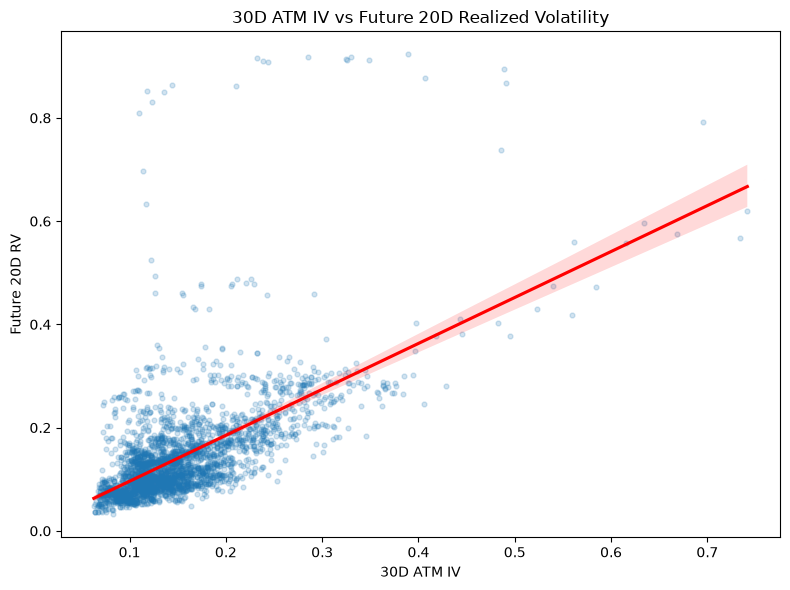

In [435]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.regplot(
    data=eda,
    x='atm_iv_30d',
    y='future_rv_20d',
    scatter_kws={'alpha': 0.2, 's': 12},
    line_kws={'color': 'red'},
    ax=ax
)

ax.set(
    title='30D ATM IV vs Future 20D Realized Volatility',
    xlabel='30D ATM IV',
    ylabel='Future 20D RV'
)

plt.tight_layout()
plt.show()

rr_25_30d              -0.544868
atm_term_slope_30_90   -0.542212
bf_25_30d              -0.059766
rv_20d                  0.514680
atm_iv_90d              0.577276
atm_iv_60d              0.595951
vix_decimal             0.616711
atm_iv_30d              0.621735
atm_iv_14d              0.638566
Name: future_rv_20d, dtype: float64


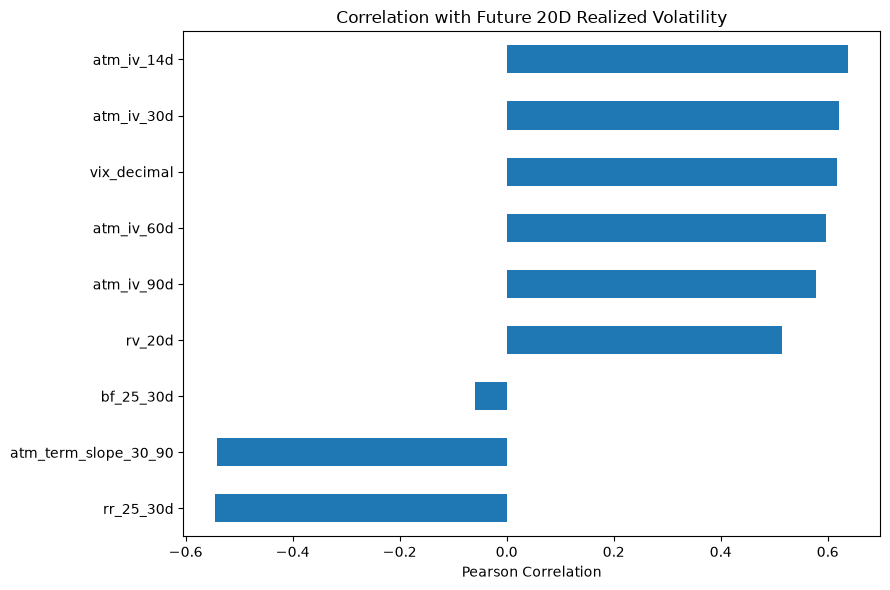

In [436]:
predictors = [
    'rv_20d',
    'vix_decimal',
    'atm_iv_14d',
    'atm_iv_30d',
    'atm_iv_60d',
    'atm_iv_90d',
    'rr_25_30d',
    'bf_25_30d',
    'atm_term_slope_30_90'
]

correlations = (
    eda[predictors + ['future_rv_20d']]
    .corr()
    ['future_rv_20d']
    .drop('future_rv_20d')
    .sort_values()
)

print(correlations)

correlations.plot.barh(figsize=(9, 6))
plt.title('Correlation with Future 20D Realized Volatility')
plt.xlabel('Pearson Correlation')
plt.tight_layout()
plt.show()

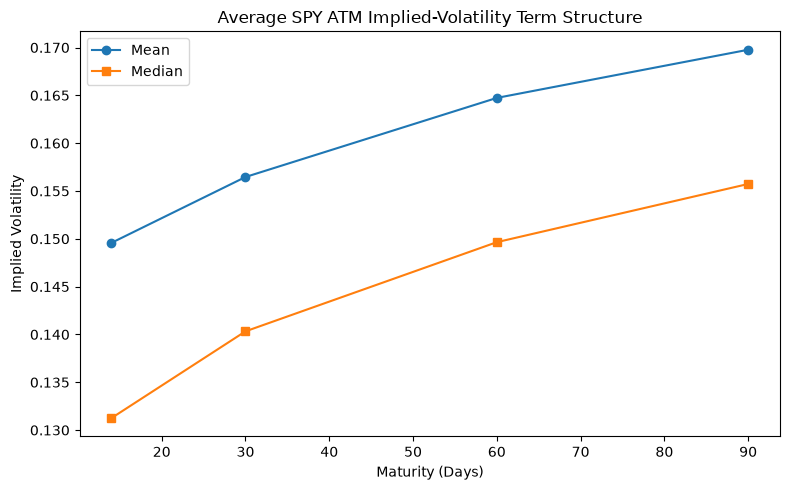

In [437]:
maturities = [14, 30, 60, 90]

atm_cols = [
    f'atm_iv_{m}d'
    for m in maturities
]

mean_iv = eda[atm_cols].mean()
median_iv = eda[atm_cols].median()

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(maturities, mean_iv, marker='o', label='Mean')
ax.plot(maturities, median_iv, marker='s', label='Median')

ax.set(
    title='Average SPY ATM Implied-Volatility Term Structure',
    xlabel='Maturity (Days)',
    ylabel='Implied Volatility'
)

ax.legend()
plt.tight_layout()
plt.show()

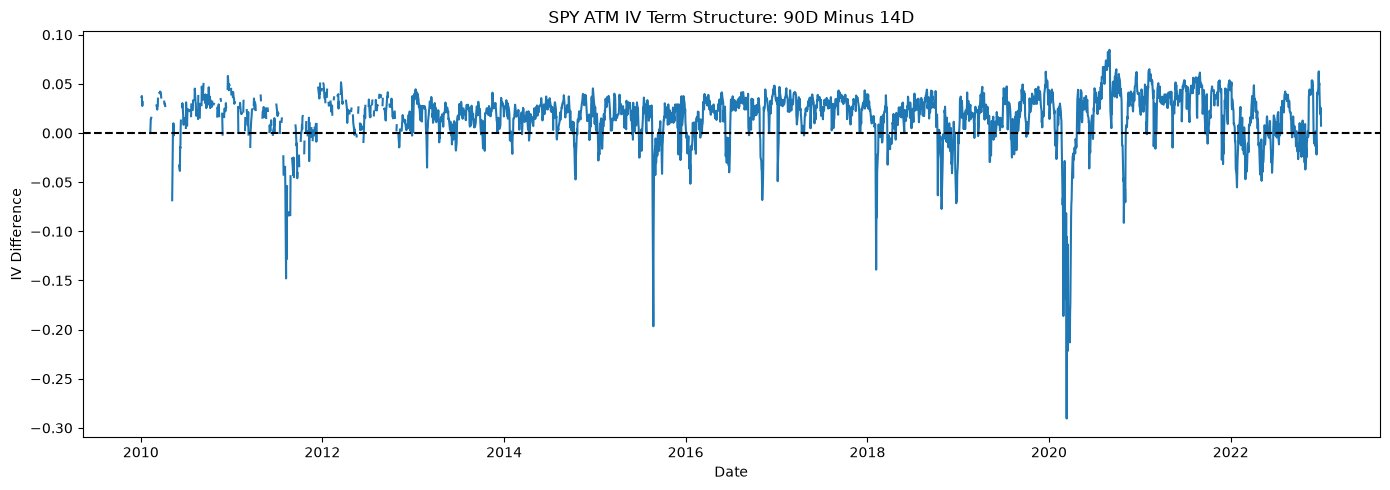

In [438]:
eda['atm_term_slope_14_90'] = (
    eda['atm_iv_90d'] - eda['atm_iv_14d']
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    eda['date'],
    eda['atm_term_slope_14_90']
)

ax.axhline(0, color='black', linestyle='--')

ax.set(
    title='SPY ATM IV Term Structure: 90D Minus 14D',
    xlabel='Date',
    ylabel='IV Difference'
)

plt.tight_layout()
plt.show()

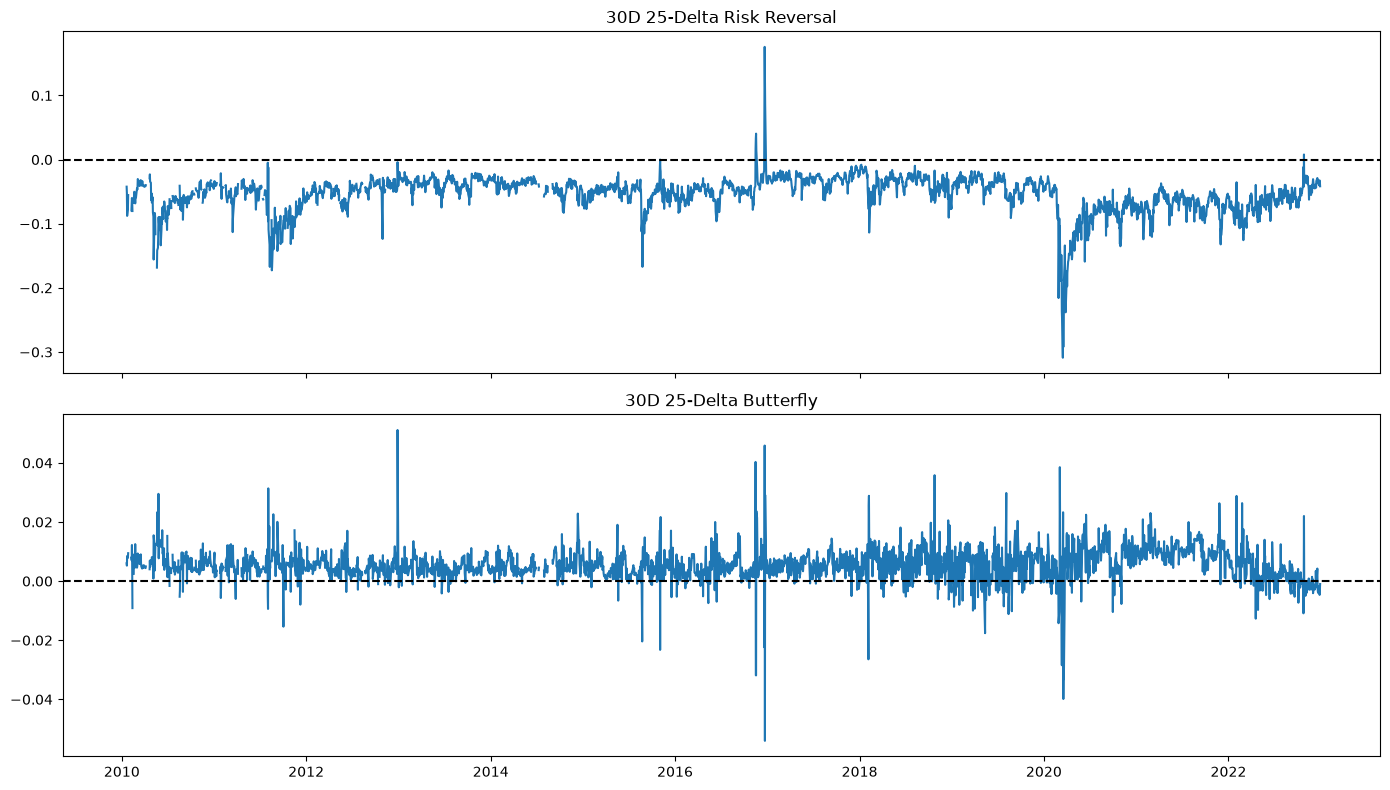

In [439]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

axes[0].plot(
    eda['date'],
    eda['rr_25_30d']
)

axes[0].axhline(0, color='black', linestyle='--')
axes[0].set_title('30D 25-Delta Risk Reversal')

axes[1].plot(
    eda['date'],
    eda['bf_25_30d']
)

axes[1].axhline(0, color='black', linestyle='--')
axes[1].set_title('30D 25-Delta Butterfly')

plt.tight_layout()
plt.show()

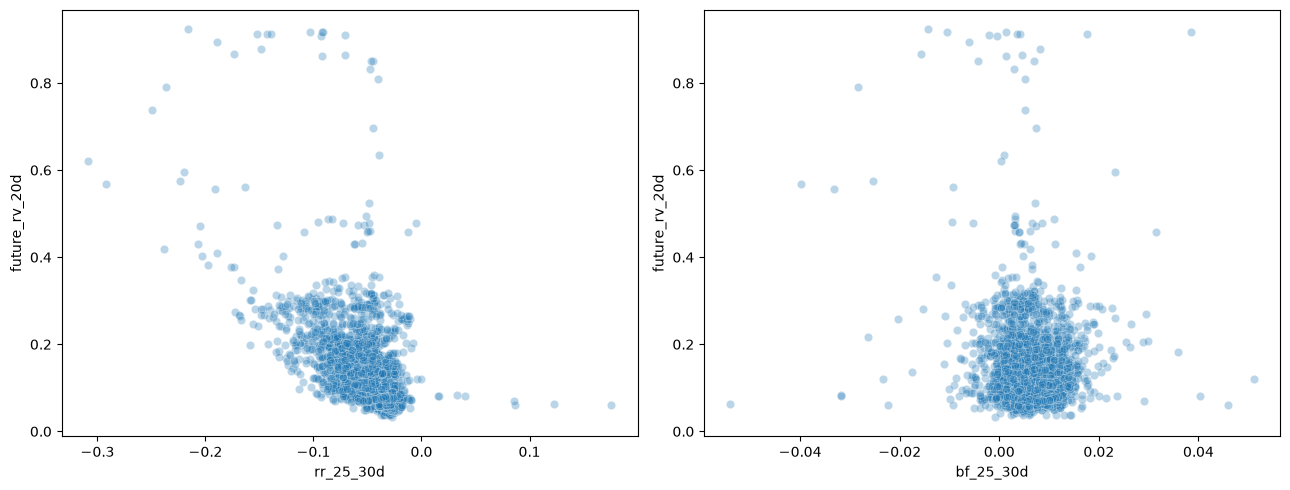

In [440]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=eda,
    x='rr_25_30d',
    y='future_rv_20d',
    alpha=0.3,
    ax=axes[0]
)

sns.scatterplot(
    data=eda,
    x='bf_25_30d',
    y='future_rv_20d',
    alpha=0.3,
    ax=axes[1]
)

plt.tight_layout()
plt.show()

In [441]:
eda['volatility_regime'] = pd.cut(
    eda['rv_20d'],
    bins=[0, 0.15, 0.30, np.inf],
    labels=['Low', 'Medium', 'High'],
    include_lowest=True
)

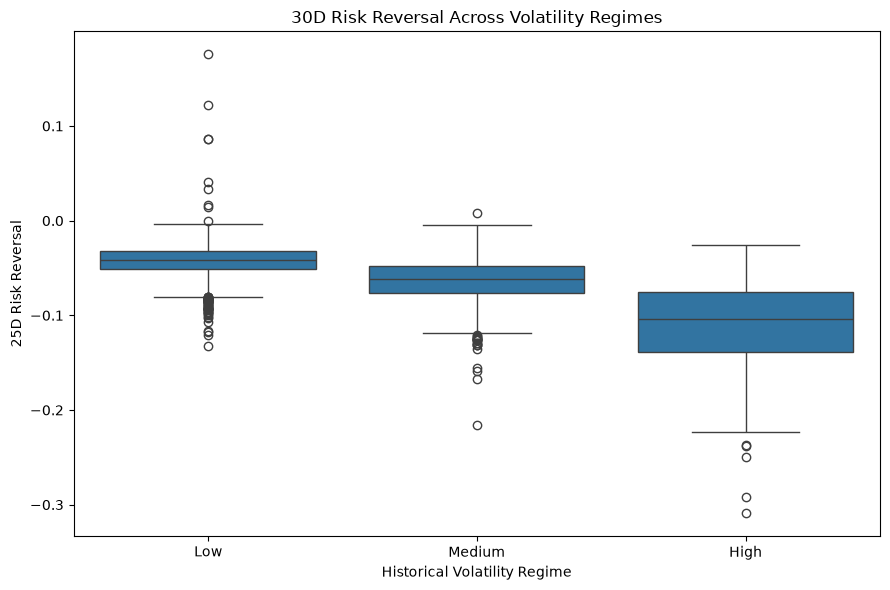

In [442]:
fig, ax = plt.subplots(figsize=(9, 6))

sns.boxplot(
    data=eda,
    x='volatility_regime',
    y='rr_25_30d',
    order=['Low', 'Medium', 'High'],
    ax=ax
)

ax.set(
    title='30D Risk Reversal Across Volatility Regimes',
    xlabel='Historical Volatility Regime',
    ylabel='25D Risk Reversal'
)

plt.tight_layout()
plt.show()

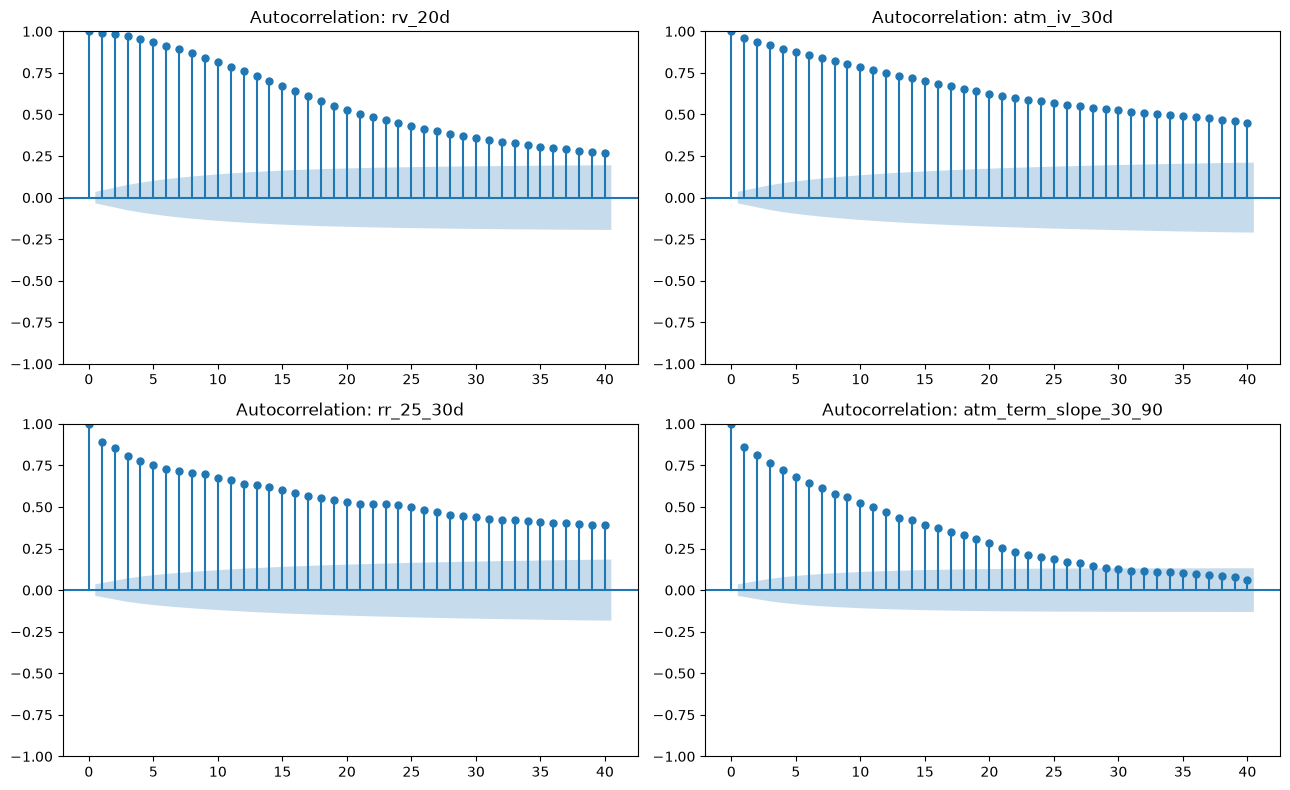

In [443]:
from statsmodels.graphics.tsaplots import plot_acf

features = [
    'rv_20d',
    'atm_iv_30d',
    'rr_25_30d',
    'atm_term_slope_30_90'
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, feature in zip(axes.flat, features):
    series = eda[feature].dropna()

    plot_acf(
        series,
        lags=40,
        ax=ax,
        title=f'Autocorrelation: {feature}'
    )

plt.tight_layout()
plt.show()

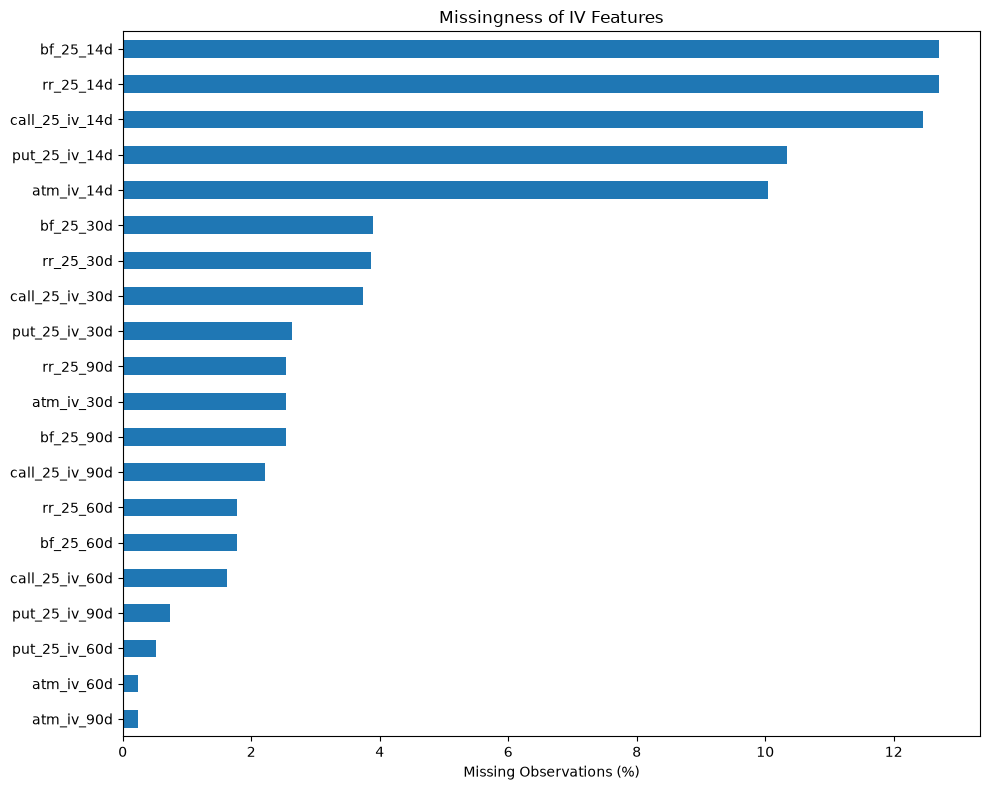

In [447]:
iv_cols = [
    f'{feature}_{m}d'
    for m in [14, 30, 60, 90]
    for feature in [
        'atm_iv',
        'put_25_iv',
        'call_25_iv',
        'rr_25',
        'bf_25'
    ]
]

missing_pct = (
    eda[iv_cols]
    .isna()
    .mean()
    .mul(100)
    .sort_values()
)

missing_pct.plot.barh(figsize=(10, 8))

plt.title('Missingness of IV Features')
plt.xlabel('Missing Observations (%)')
plt.tight_layout()
plt.show()

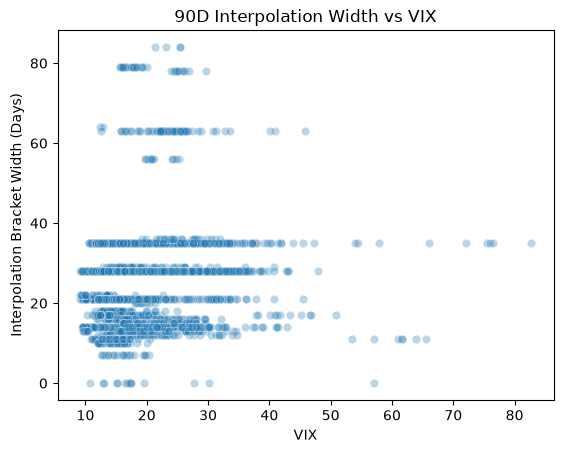

In [449]:
sns.scatterplot(
    data=eda,
    x='vix_close',
    y='atm_iv_90d_bracket_width',
    alpha=0.3
)

plt.title('90D Interpolation Width vs VIX')
plt.xlabel('VIX')
plt.ylabel('Interpolation Bracket Width (Days)')
plt.show()

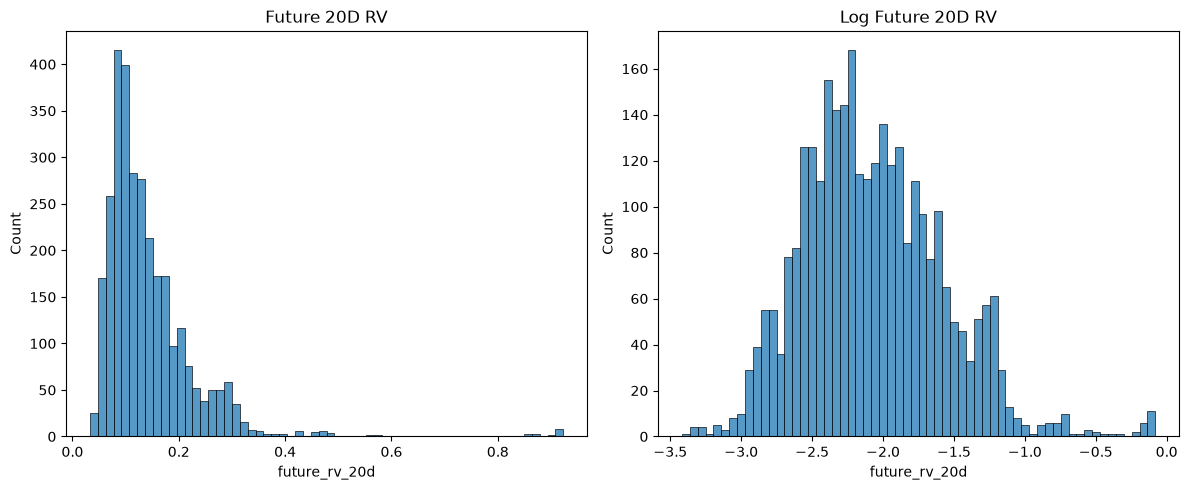

In [450]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    eda['future_rv_20d'].dropna(),
    bins=60,
    ax=axes[0]
)

axes[0].set_title('Future 20D RV')

sns.histplot(
    np.log(eda['future_rv_20d'].dropna().clip(lower=1e-8)),
    bins=60,
    ax=axes[1]
)

axes[1].set_title('Log Future 20D RV')

plt.tight_layout()
plt.show()